# Upload data → train TransGNN → see Dice and all metrics

**In Google Colab: choose a GPU runtime, then choose Runtime → Run all.** Upload the three files when prompted. No training/upload switches need changing.

1. Upload **DRIVE `datasets.zip`** (training/test images, vessel labels and FOV masks).
2. Upload **STARE images archive**.
3. Upload **STARE `labels-ah.tar`** (ground-truth vessel masks).
4. Training starts automatically. **Dice and other test metrics appear after DRIVE finishes and after every STARE fold**, followed by the complete summary, predictions and model download links.

Your full model is **ResNet34 CNN + Transformer + U-Net decoder + GNN refinement**. DRIVE and STARE are trained separately. The default uses one seed, DRIVE's 14/3/3 internal split of its 20 labeled training images and STARE's 20-fold leave-one-out protocol. That means **21 training runs**, so GPU training will take substantial time; the notebook reports scores as they become available.

Scores are calculated from your uploaded labels after training. There are no prefilled or promised Dice scores. Keep the Colab session connected and download your outputs before its runtime is removed.

## 1. Install dependencies

In [ ]:
import sys, subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'torch>=2.2', 'torchvision>=0.17', 'numpy>=1.26', 'scipy>=1.11',
    'scikit-image>=0.22', 'pandas>=2.0', 'Pillow>=10', 'matplotlib>=3.9', 'nbformat>=5.9', 'ipython>=8'])


0

## 2. Your model settings (ready to run)
The full model, uploads and final evaluation are enabled. Defaults: 256×256 patches, 80 maximum CNN epochs and 50 maximum GNN epochs, with validation early stopping. No other models are trained by default. You can leave the code below unchanged.

In [ ]:
import os, sys, json, random, hashlib, platform, time, gc, re, gzip, shutil, tarfile, zipfile
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tv_models
from scipy import ndimage as ndi, stats
from scipy.spatial import cKDTree
from skimage import exposure
from skimage.morphology import skeletonize
from skimage.metrics import structural_similarity

@dataclass(frozen=True)
class Config:
    mode: str = 'final'  # Set 'final' only after freezing all choices.
    output: str = 'transgnn_results'
    datasets: tuple = ('DRIVE', 'STARE')
    seeds: tuple = (42,)
    models: tuple = ('transgnn',)
    pretrained: bool = True
    patch: int = 256
    stride: int = 192
    patches_per_image: int = 16
    batch_size: int = 4
    epochs: int = 80
    gnn_epochs: int = 50
    freeze_epochs: int = 5
    patience: int = 10
    encoder_lr: float = 3e-5
    lr: float = 1e-4
    weight_decay: float = 1e-4
    scheduler_patience: int = 4
    clip_grad: float = 1.0
    embed_dim: int = 256
    transformer_depth: int = 2
    heads: int = 8
    dropout: float = 0.1
    clahe: bool = True
    clahe_clip: float = 0.01
    clahe_kernel: tuple = (32, 32)
    vessel_patch_fraction: float = 0.5
    hard_mining: bool = True
    hard_start: int = 10
    hard_fraction: float = 0.25
    elastic_probability: float = 0.3
    elastic_alpha: float = 30.0
    elastic_sigma: float = 5.0
    brightness_range: tuple = (0.85, 1.15)
    contrast_range: tuple = (0.85, 1.15)
    gamma_range: tuple = (0.9, 1.1)
    boundary_weight: float = 0.0  # Optional, locked ablation.
    topology_weight: float = 0.0  # Optional soft-clDice ablation.
    tta: bool = False
    thresholds: tuple = tuple(round(x / 100, 2) for x in range(20, 81, 5))
    graph_candidate: float = 0.2
    graph_step: int = 8
    graph_bridge_radius: float = 12.0
    graph_bridge_probability: float = 0.1
    graph_hidden: int = 64
    graph_layers: int = 3
    graph_radius: float = 8.0
    graph_mix: float = 0.5
    thin_radius: float = 2.0
    junction_radius: int = 5
    fov_threshold: int = 10
    bootstrap_samples: int = 2000

CFG = Config()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    # Sparse CUDA index_add can be nondeterministic; log warnings rather than claim bitwise reproducibility.
    torch.use_deterministic_algorithms(True, warn_only=True)


def json_write(path, obj):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    def clean(x):
        if isinstance(x, dict): return {str(k): clean(v) for k, v in x.items()}
        if isinstance(x, (list, tuple)): return [clean(v) for v in x]
        if isinstance(x, np.generic): return clean(x.item())
        if isinstance(x, float) and not np.isfinite(x): return None
        if isinstance(x, Path): return str(x)
        return x
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(clean(obj), indent=2)); tmp.replace(path)


def synchronize():
    if DEVICE.type == 'cuda': torch.cuda.synchronize()

print('Device:', DEVICE, '| PyTorch:', torch.__version__)


Device: cuda | PyTorch: 2.11.0+cu128


## 3. Load the model and scoring functions
Run this section unchanged. It defines your CNN–Transformer model, graph refinement, training loops and metrics. Expand the code cells if you want to inspect the implementation.

In [ ]:
def safe_extract(archive, destination):
    from pathlib import Path, PurePosixPath
    import zipfile, tarfile, shutil, gzip, stat

    root = Path(destination).resolve()
    root.mkdir(parents=True, exist_ok=True)

    def get_target(name, is_directory, size):
        name = name.replace("\\", "/")

        # Ignore harmless empty/root directory entries.
        if name in ("", ".", "./", "/"):
            if is_directory or size == 0:
                return None
            raise ValueError(f"Invalid archive entry: {name!r}")

        parts = PurePosixPath(name)
        if (
            "\x00" in name
            or parts.is_absolute()
            or ".." in parts.parts
            or ":" in parts.parts[0]
        ):
            raise ValueError(f"Unsafe archive entry: {name!r}")

        target = root.joinpath(*parts.parts).resolve()
        if not target.is_relative_to(root):
            raise ValueError(f"Unsafe archive entry: {name!r}")

        return target

    if zipfile.is_zipfile(archive):
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                mode = member.external_attr >> 16
                if stat.S_ISLNK(mode):
                    raise ValueError("Archive contains a symbolic link")

                is_directory = (
                    member.is_dir()
                    or stat.S_ISDIR(mode)
                    or member.filename.endswith("\\")
                )
                target = get_target(
                    member.filename, is_directory, member.file_size
                )

                if target is None:
                    continue
                if is_directory:
                    target.mkdir(parents=True, exist_ok=True)
                else:
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with z.open(member) as src, target.open("wb") as dst:
                        shutil.copyfileobj(src, dst)
    else:
        with tarfile.open(archive, "r:*") as t:
            for member in t.getmembers():
                if not (member.isfile() or member.isdir()):
                    raise ValueError("Archive contains a link or special file")

                target = get_target(
                    member.name, member.isdir(), member.size
                )

                if target is None:
                    continue
                if member.isdir():
                    target.mkdir(parents=True, exist_ok=True)
                else:
                    target.parent.mkdir(parents=True, exist_ok=True)
                    with t.extractfile(member) as src, target.open("wb") as dst:
                        shutil.copyfileobj(src, dst)

    for path in root.rglob("*.ppm.gz"):
        with gzip.open(path, "rb") as src:
            with path.with_suffix("").open("wb") as dst:
                shutil.copyfileobj(src, dst)

DRIVE_ROOT = Path('drive_data')
STARE_IMAGE_ROOT = Path('stare_images_raw')
STARE_LABEL_ROOT = Path('stare_labels_raw')
STARE_FOV_ROOT = None

@dataclass(frozen=True)
class Record:
    dataset: str
    id: str
    image: str
    label: str
    fov: str | None = None
    split: str = ''


def unique_index(paths, key):
    out = {}
    for p in paths:
        k = key(p)
        if k in out: raise ValueError(f'Duplicate ID {k}: {out[k]} and {p}')
        out[k] = str(p)
    return out


def discover_records():
    records = {}
    if 'DRIVE' in CFG.datasets:
        # The supplied archive has labels only for the official training images.
        images = unique_index([
            p for p in DRIVE_ROOT.rglob('*')
            if p.is_file() and p.suffix.lower() in ('.tif', '.tiff', '.png')
            and p.parent.name == 'images' and 'training' in p.parts
        ], lambda p: p.name.split('_')[0])
        labels = unique_index([
            p for p in DRIVE_ROOT.rglob('*')
            if p.is_file() and p.parent.name == '1st_manual' and 'training' in p.parts
        ], lambda p: p.name.split('_')[0])
        fovs = unique_index([
            p for p in DRIVE_ROOT.rglob('*')
            if p.is_file() and p.parent.name == 'mask' and 'training' in p.parts
        ], lambda p: p.name.split('_')[0])
        if len(images) != 20:
            raise ValueError(f'Expected 20 labeled DRIVE training images; found {len(images)}')
        missing = set(images) - (set(labels) & set(fovs))
        if missing:
            raise ValueError(f'Missing DRIVE training vessel labels or FOV masks for: {sorted(missing)}')
        records['DRIVE'] = [Record('DRIVE', ident, images[ident], labels[ident],
                                  fovs[ident], 'training') for ident in sorted(images)]
    if 'STARE' in CFG.datasets:
        extensions = ('.ppm', '.png', '.tif', '.tiff')
        key = lambda p: re.sub(r'\.(ah|vk)$', '', p.stem)
        images = unique_index([p for p in STARE_IMAGE_ROOT.rglob('*')
                               if p.is_file() and p.suffix.lower() in extensions], key)
        labels = unique_index([p for p in STARE_LABEL_ROOT.rglob('*')
                               if p.is_file() and p.suffix.lower() in extensions], key)
        if not labels:
            raise ValueError('No STARE labels found. Upload labels-ah.tar in Section 6.')
        missing = set(labels) - set(images)
        if missing:
            raise ValueError(f'STARE labels with no matching source image: {sorted(missing)}')
        ids = sorted(set(images) & set(labels))
        if len(ids) != 20:
            raise ValueError(f'Expected 20 STARE image/label pairs; found {len(ids)}. Use one annotator only.')
        fovs = {} if STARE_FOV_ROOT is None else unique_index([
            p for p in Path(STARE_FOV_ROOT).rglob('*')
            if p.is_file() and p.suffix.lower() in extensions], key)
        records['STARE'] = [Record('STARE', i, images[i], labels[i], fovs.get(i)) for i in ids]
    for dataset, items in records.items():
        hashes = [hashlib.sha256(Path(r.image).read_bytes()).hexdigest() for r in items]
        if len(set(hashes)) != len(hashes):
            raise ValueError(f'Duplicate source images in {dataset}')
    return records


@lru_cache(maxsize=64)
def load_record(r, cfg):
    rgb = np.asarray(Image.open(r.image).convert('RGB'), dtype=np.float32) / 255.
    y = np.asarray(Image.open(r.label).convert('L')) > 127
    if rgb.shape[:2] != y.shape: raise ValueError(f'Shape mismatch: {r.id}')
    if r.fov:
        fov = np.asarray(Image.open(r.fov).convert('L')) > 127
    else:
        # Image-derived STARE FOV, never derived from the vessel annotation.
        fov = ndi.binary_fill_holes(rgb.max(-1) > cfg.fov_threshold / 255.)
        cc, n = ndi.label(fov)
        if n: fov = cc == (np.bincount(cc.ravel())[1:].argmax() + 1)
    if fov.shape != y.shape or not fov.any(): raise ValueError(f'Invalid FOV: {r.id}')
    enhanced = rgb.copy()
    if cfg.clahe:
        enhanced[..., 1] = exposure.equalize_adapthist(
            enhanced[..., 1], kernel_size=cfg.clahe_kernel, clip_limit=cfg.clahe_clip)
    return rgb, enhanced, y & fov, fov


def make_splits(records, seed, mode):
    order = list(np.random.default_rng(seed).permutation(len(records)))
    if records[0].dataset == 'DRIVE':
        if len(records) != 20:
            raise ValueError('DRIVE internal holdout requires the 20 labeled training images')
        yield ('internal_holdout', [records[i] for i in order[:14]],
               [records[i] for i in order[14:17]],
               [records[i] for i in order[17:]] if mode == 'final' else [])
    elif mode == 'development':
        yield ('development', [records[i] for i in order[2:]], [records[order[0]]], [])
    else:
        for k, test_i in enumerate(order):
            val_i = order[(k + 1) % len(order)]
            yield (f'fold_{records[test_i].id}',
                   [r for i, r in enumerate(records) if i not in (test_i, val_i)],
                   [records[val_i]], [records[test_i]])



def assert_disjoint(train, val, test):
    sets = [{(r.dataset, r.id) for r in group} for group in (train, val, test)]
    assert sets[0] and sets[1]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])

class PatchDataset(Dataset):
    def __init__(self, records, cfg):
        self.records, self.cfg = list(records), cfg
        self.hard = {}; self.epoch = 0
    def __len__(self): return len(self.records) * self.cfg.patches_per_image
    def __getitem__(self, index):
        r = self.records[index // self.cfg.patches_per_image]; c = self.cfg
        _, image, y, fov = load_record(r, c)
        h, w = y.shape; p = c.patch
        pad = ((0, max(0, p-h)), (0, max(0, p-w)))
        image = np.pad(image, pad+((0, 0),), mode='constant')
        y = np.pad(y, pad); fov = np.pad(fov, pad); h, w = y.shape
        if self.epoch >= c.hard_start and r.id in self.hard and random.random() < c.hard_fraction:
            cy, cx = random.choice(self.hard[r.id])
        elif random.random() < c.vessel_patch_fraction and y.any():
            cy, cx = random.choice(np.argwhere(y))
        else:
            cy, cx = random.randrange(h), random.randrange(w)
        top, left = int(np.clip(cy-p//2, 0, h-p)), int(np.clip(cx-p//2, 0, w-p))
        x = image[top:top+p, left:left+p].copy()
        target = y[top:top+p, left:left+p].astype(np.float32)
        mask = fov[top:top+p, left:left+p].astype(np.float32)
        arrays = [x, target, mask]
        for axis in (0, 1):
            if random.random() < .5: arrays = [np.flip(a, axis=axis) for a in arrays]
        turns = random.randrange(4); arrays = [np.rot90(a, turns) for a in arrays]
        if random.random() < c.elastic_probability:
            yy, xx = np.mgrid[:p, :p]
            dy = ndi.gaussian_filter(np.random.uniform(-1, 1, (p, p)), c.elastic_sigma)*c.elastic_alpha
            dx = ndi.gaussian_filter(np.random.uniform(-1, 1, (p, p)), c.elastic_sigma)*c.elastic_alpha
            coords = [yy+dy, xx+dx]
            arrays[0] = np.stack([ndi.map_coordinates(arrays[0][..., k], coords, order=1, mode='reflect') for k in range(3)], -1)
            arrays[1:] = [ndi.map_coordinates(a, coords, order=0, mode='constant') for a in arrays[1:]]
        x, target, mask = arrays
        x = (x - .5)*random.uniform(*c.contrast_range)+.5
        x = np.clip(x*random.uniform(*c.brightness_range), 0, 1)**random.uniform(*c.gamma_range)
        x = (x - np.array([.485, .456, .406])) / np.array([.229, .224, .225])
        return tuple(torch.from_numpy(np.ascontiguousarray(a)).float() for a in
                     (x.transpose(2, 0, 1), target[None], mask[None]))

In [ ]:
class DoubleConv(nn.Module):
    def __init__(self, a, b):
        super().__init__()
        self.block = nn.Sequential(nn.Conv2d(a,b,3,padding=1), nn.GroupNorm(8,b), nn.ReLU(),
                                   nn.Conv2d(b,b,3,padding=1), nn.GroupNorm(8,b), nn.ReLU())
    def forward(self,x): return self.block(x)

class TransformerBottleneck(nn.Module):
    def __init__(self, channels, cfg):
        super().__init__()
        self.proj = nn.Conv2d(channels, cfg.embed_dim, 1)
        # Created before the optimizer, never replaced in forward().
        self.pos_embed = nn.Parameter(torch.zeros(1,cfg.embed_dim,8,8))
        nn.init.trunc_normal_(self.pos_embed,std=.02)
        layer = nn.TransformerEncoderLayer(cfg.embed_dim,cfg.heads,4*cfg.embed_dim,
                 dropout=cfg.dropout,activation='gelu',batch_first=True,norm_first=True)
        self.transformer = nn.TransformerEncoder(layer,cfg.transformer_depth,enable_nested_tensor=False)
        self.out = nn.Conv2d(cfg.embed_dim,channels,1)
    def forward(self,x):
        z = self.proj(x); b,c,h,w = z.shape
        z = z + F.interpolate(self.pos_embed, size=(h,w),mode='bilinear',align_corners=False)
        z = self.transformer(z.flatten(2).transpose(1,2)).transpose(1,2).reshape(b,c,h,w)
        return x + self.out(z)

class Segmenter(nn.Module):
    def __init__(self, name, cfg):
        super().__init__(); self.name = name; self.is_resnet = name != 'unet'
        if self.is_resnet:
            weights = tv_models.ResNet34_Weights.IMAGENET1K_V1 if cfg.pretrained else None
            net = tv_models.resnet34(weights=weights)
            self.encoder = nn.ModuleList([nn.Sequential(net.conv1,net.bn1,net.relu),
                nn.Sequential(net.maxpool,net.layer1),net.layer2,net.layer3,net.layer4])
            channels = [64,64,128,256,512]
        else:
            channels = [32,64,128,256,512]
            self.encoder = nn.ModuleList([DoubleConv(3,32)] + [
                nn.Sequential(nn.MaxPool2d(2),DoubleConv(a,b)) for a,b in zip(channels[:-1],channels[1:])])
        self.bottleneck = TransformerBottleneck(512,cfg) if name in ('transformer','transgnn') else nn.Identity()
        self.decoder = nn.ModuleList([DoubleConv(512+channels[3],256),DoubleConv(256+channels[2],128),
                                      DoubleConv(128+channels[1],64),DoubleConv(64+channels[0],32)])
        self.head = nn.Conv2d(32,1,1)
    def forward(self,x,return_features=False):
        size = x.shape[-2:]; skips=[]; z=x
        for layer in self.encoder: z=layer(z); skips.append(z)
        z=self.bottleneck(z)
        for block,skip in zip(self.decoder,reversed(skips[:-1])):
            z=block(torch.cat([F.interpolate(z,size=skip.shape[-2:],mode='bilinear',align_corners=False),skip],1))
        z=F.interpolate(z,size=size,mode='bilinear',align_corners=False)
        logits=self.head(z)
        return (logits,z) if return_features else logits
    def param_groups(self,cfg):
        enc=list(self.encoder.parameters()); ids={id(p) for p in enc}
        return [{'params':enc,'lr':cfg.encoder_lr if self.is_resnet else cfg.lr},
                {'params':[p for p in self.parameters() if id(p) not in ids],'lr':cfg.lr}]


def soft_skeleton(x, iterations=10):
    def erode(z): return torch.minimum(-F.max_pool2d(-z,(3,1),1,(1,0)), -F.max_pool2d(-z,(1,3),1,(0,1)))
    def opened(z): return F.max_pool2d(erode(z),3,1,1)
    skel=F.relu(x-opened(x))
    for _ in range(iterations):
        x=erode(x); d=F.relu(x-opened(x)); skel=skel+F.relu(d-skel*d)
    return skel


def combo_loss(logits,y,fov,cfg):
    p=logits.sigmoid(); eps=1e-6
    def mean(v): return (v*fov).sum()/fov.sum().clamp_min(1)
    bce=F.binary_cross_entropy_with_logits(logits,y,reduction='none')
    pt=p*y+(1-p)*(1-y); alpha=.8*y+.2*(1-y)
    dice=1-(2*(p*y*fov).sum()+eps)/((p*fov).sum()+(y*fov).sum()+eps)
    loss=.3*mean(bce)+.5*dice+.2*mean(alpha*(1-pt).pow(2)*bce)
    if cfg.boundary_weight:
        # Boundary-weighted BCE, explicitly distinct from signed-distance boundary loss.
        boundary=F.max_pool2d(y,3,1,1)+F.max_pool2d(-y,3,1,1)
        loss=loss+cfg.boundary_weight*mean(bce*boundary)
    if cfg.topology_weight:
        sp,sy=soft_skeleton(p*fov),soft_skeleton(y*fov)
        precision=((sp*y).sum()+eps)/(sp.sum()+eps)
        recall=((sy*p).sum()+eps)/(sy.sum()+eps)
        loss=loss+cfg.topology_weight*(1-2*precision*recall/(precision+recall+eps))
    return loss


def origins(length,patch,stride):
    assert 0 < stride <= patch
    return sorted(set(list(range(0,max(1,length-patch+1),stride))+[max(0,length-patch)]))

@torch.no_grad()
def predict_image(model, enhanced, cfg, features=False):
    """Native-resolution overlapping tiles; avoids train/eval resolution mismatch."""
    model.eval(); h,w=enhanced.shape[:2]; p=cfg.patch
    x=np.pad(enhanced,((0,max(0,p-h)),(0,max(0,p-w)),(0,0)))
    hh,ww=x.shape[:2]; prob=np.zeros((hh,ww),np.float32); count=np.zeros_like(prob)
    deep=np.zeros((32,hh,ww),np.float32) if features else None
    transforms=[()] if not cfg.tta else [(),(-1,),(-2,),(-2,-1)]
    for y in origins(hh,p,cfg.stride):
        for xx in origins(ww,p,cfg.stride):
            tile=(x[y:y+p,xx:xx+p]-[.485,.456,.406])/[.229,.224,.225]
            t=torch.as_tensor(tile.transpose(2,0,1).copy(),dtype=torch.float32,device=DEVICE)[None]
            ps=[]; fs=[]
            for dims in transforms:
                inp=t.flip(dims) if dims else t
                logits,feat=model(inp,True)
                if dims: logits=logits.flip(dims); feat=feat.flip(dims)
                ps.append(logits.sigmoid()); fs.append(feat)
            prob[y:y+p,xx:xx+p]+=torch.stack(ps).mean(0)[0,0].cpu().numpy()
            count[y:y+p,xx:xx+p]+=1
            if features: deep[:,y:y+p,xx:xx+p]+=torch.stack(fs).mean(0)[0].cpu().numpy()
    prob=(prob/count)[:h,:w]
    if not np.isfinite(prob).all(): raise FloatingPointError('Nonfinite inference output')
    return prob, (deep[:,:h,:w]/count[None,:h,:w] if features else None)


In [ ]:
def ratio(a,b,empty=np.nan): return float(a/b) if b else float(empty)

def dice_score(y,p,fov):
    y=y[fov].astype(bool); p=p[fov].astype(bool)
    return ratio(2*np.count_nonzero(y&p),np.count_nonzero(y)+np.count_nonzero(p),1.)


def surface_distances(y,p):
    sy=y & ~ndi.binary_erosion(y); sp=p & ~ndi.binary_erosion(p)
    if not sy.any() and not sp.any(): return 0.,0.,0.
    if not sy.any() or not sp.any(): return np.inf,np.inf,np.inf
    a=ndi.distance_transform_edt(~sy)[sp]; b=ndi.distance_transform_edt(~sp)[sy]
    # Max of directed 95th percentiles; ASSD pools both surfaces with point weighting.
    return float(max(np.percentile(a,95),np.percentile(b,95))),float(np.r_[a,b].mean()),float(max(a.max(),b.max()))


def topology_points(mask):
    sk=skeletonize(mask); degree=ndi.convolve(sk.astype(int),np.ones((3,3),int),mode='constant')-sk
    return sk,sk&(degree==1),sk&(degree>=3)


def segmentation_metrics(y,p,fov,cfg):
    y=y.astype(bool)&fov; p=p.astype(bool)&fov
    a,b=y[fov],p[fov]
    tp=np.count_nonzero(a&b); tn=np.count_nonzero(~a&~b)
    fp=np.count_nonzero(~a&b); fn=np.count_nonzero(a&~b)
    hd95,assd,hd=surface_distances(y,p)
    sy,ey,jy=topology_points(y); sp,ep,jp=topology_points(p)
    tprec=ratio(np.count_nonzero(sp&y),sp.sum(),0.)
    tsens=ratio(np.count_nonzero(sy&p),sy.sum(),0.)
    cldice=ratio(2*tprec*tsens,tprec+tsens,1. if not (y.any() or p.any()) else 0.)
    radius=ndi.distance_transform_edt(y)
    # Width class follows nearest GT centerline radius, not boundary-pixel distance.
    if sy.any():
        _, inds=ndi.distance_transform_edt(~sy,return_indices=True)
        local_radius=radius[tuple(inds)]
    else: local_radius=np.zeros_like(radius)
    thin=y&(local_radius<=cfg.thin_radius); thick=y&~thin
    jr=ndi.binary_dilation(jy,iterations=cfg.junction_radius)&fov
    _,ssim_map=structural_similarity(y.astype(float),p.astype(float),data_range=1.,win_size=7,full=True)
    interior=ndi.binary_erosion(fov,structure=np.ones((7,7),bool),border_value=0)
    ssim=float(ssim_map[interior].mean()) if interior.any() else np.nan
    cy=ndi.label(y,np.ones((3,3)))[1]; cp=ndi.label(p,np.ones((3,3)))[1]
    def point_recall(source,dest):
        return ratio(np.count_nonzero(source&ndi.binary_dilation(dest,iterations=cfg.junction_radius)),source.sum())
    return dict(dice=dice_score(y,p,fov),iou=ratio(tp,tp+fp+fn,1.),sensitivity=ratio(tp,tp+fn),
        specificity=ratio(tn,tn+fp),precision=ratio(tp,tp+fp),accuracy=ratio(tp+tn,len(a)),
        ssim=ssim,hd95=hd95,assd=assd,hd=hd,cldice=cldice,
        thin_sensitivity=ratio(np.count_nonzero(p&thin),thin.sum()),
        thick_sensitivity=ratio(np.count_nonzero(p&thick),thick.sum()),
        junction_dice=dice_score(y,p,jr) if jr.any() else np.nan,
        junction_recall=point_recall(jy,jp),endpoint_recall=point_recall(ey,ep),
        endpoint_count_error=abs(int(ep.sum())-int(ey.sum())),
        component_count_error=abs(cp-cy),pred_components=cp,gt_components=cy)


def choose_threshold(predictions, cfg):
    # Only validation tuples may be supplied by the orchestration code.
    rows=[{'threshold':t,'dice':float(np.mean([dice_score(y,p>=t,f) for p,y,f in predictions]))}
          for t in cfg.thresholds]
    best=max(rows,key=lambda r:(r['dice'],-abs(r['threshold']-.5)))
    return best['threshold'],rows


def summarize_metrics(frame,cfg):
    keys=list(segmentation_metrics(np.zeros((9,9),bool),np.zeros((9,9),bool),np.ones((9,9),bool),cfg))
    result=[]; rng=np.random.default_rng(2026)
    # Images, not pixels or repeated seeds, are the descriptive bootstrap units.
    grouped=frame.groupby(['dataset','model','image_id'])[keys].mean(numeric_only=True).reset_index()
    for (dataset,model),sub in grouped.groupby(['dataset','model']):
        for metric in keys:
            v=sub[metric].to_numpy(float); finite=v[np.isfinite(v)]; n=len(finite)
            boot=np.mean(rng.choice(finite,(cfg.bootstrap_samples,n),replace=True),axis=1) if n else np.array([np.nan])
            has_inf=np.isinf(v).any()
            result.append(dict(dataset=dataset,model=model,metric=metric,n_images=len(v),
                n_finite=n,n_infinite=int(np.isinf(v).sum()),n_missing=int(np.isnan(v).sum()),
                mean=float(np.mean(v[~np.isnan(v)])) if (~np.isnan(v)).any() else np.nan,
                sd=float(np.std(finite,ddof=1)) if n>1 and not has_inf else np.nan,
                median=float(np.nanmedian(v)),ci_low=float(np.percentile(boot,2.5)) if not has_inf else np.nan,
                ci_high=float(np.percentile(boot,97.5)) if not has_inf else np.nan))
    return pd.DataFrame(result)


def paired_statistics(frame):
    rows=[]
    # Average each image over seeds before pairing; do not count seeds as new subjects.
    means=frame.groupby(['dataset','image_id','model']).dice.mean().unstack('model')
    for dataset in means.index.get_level_values(0).unique():
        table=means.loc[dataset]
        if 'transgnn' not in table: continue
        for base in ('unet','resnet_unet','transformer','resnet_gnn'):
            if base not in table: continue
            paired=table[[base,'transgnn']].dropna(); diff=paired.transgnn-paired[base]; n=len(diff)
            if not n: continue
            pv=1. if np.allclose(diff,0) else float(stats.wilcoxon(diff,method='auto').pvalue)
            nz=diff[diff!=0]; ranks=stats.rankdata(np.abs(nz))
            rbc=ratio(float(ranks[nz>0].sum()-ranks[nz<0].sum()),float(ranks.sum()),0.)
            rows.append(dict(dataset=dataset,comparison=f'{base} vs transgnn',n_images=n,
                delta_dice=float(diff.mean()),relative_percent=100*ratio(diff.mean(),paired[base].mean()),
                paired_dz=ratio(diff.mean(),diff.std(ddof=1)),rank_biserial=rbc,p_value=pv))
    out=pd.DataFrame(rows)
    if len(out):
        out['p_holm']=np.nan
        for _,sub in out.groupby('dataset'):
            order=sub.p_value.sort_values().index; vals=out.loc[order,'p_value'].to_numpy()
            out.loc[order,'p_holm']=np.minimum(1,np.maximum.accumulate(vals*np.arange(len(vals),0,-1)))
    return out


In [ ]:
def build_graph(prob, deep, enhanced, fov, cfg):
    """No annotation argument: graph topology/features depend only on image and predictions.
    Nodes: endpoints, junction pixels, and intermediate samples along skeleton paths.
    Edges: traced vessel segments plus short image-supported endpoint bridges.
    """
    candidate=(prob>=cfg.graph_candidate)&fov
    sk=skeletonize(candidate); pixels=[tuple(v) for v in np.argwhere(sk)]
    if not pixels: return None
    lookup=set(pixels)
    neighbors={p:[(p[0]+dy,p[1]+dx) for dy in (-1,0,1) for dx in (-1,0,1)
                  if (dy or dx) and (p[0]+dy,p[1]+dx) in lookup] for p in pixels}
    selected={p for p in pixels if len(neighbors[p])!=2}
    # Anchor a pure loop so it can be traced and sampled.
    components,n=ndi.label(sk,np.ones((3,3)))
    anchored={components[p] for p in selected}
    for label in range(1,n+1):
        if label not in anchored: selected.add(tuple(np.argwhere(components==label)[0]))
    visited=set(); paths=[]
    def edge_key(a,b): return tuple(sorted((a,b)))
    for start in sorted(selected):
        for nxt in neighbors[start]:
            if edge_key(start,nxt) in visited: continue
            path=[start,nxt]; visited.add(edge_key(start,nxt)); prev,cur=start,nxt
            while cur not in selected:
                options=[q for q in neighbors[cur] if q!=prev]
                if not options: break
                q=options[0]
                if edge_key(cur,q) in visited: break
                visited.add(edge_key(cur,q)); path.append(q); prev,cur=cur,q
            anchors=list(range(0,len(path)-1,cfg.graph_step))+[len(path)-1]
            for a,b in zip(anchors[:-1],anchors[1:]):
                selected.update((path[a],path[b])); paths.append(path[a:b+1])
    coords=np.array(sorted(selected),dtype=int); index={tuple(p):i for i,p in enumerate(coords)}
    if not len(coords): return None
    endpoints=[i for i,p in enumerate(coords) if len(neighbors[tuple(p)])==1]
    if len(endpoints)>1:
        tree=cKDTree(coords[endpoints])
        for aa,bb in sorted(tree.query_pairs(cfg.graph_bridge_radius)):
            a,b=endpoints[aa],endpoints[bb]
            if components[tuple(coords[a])]==components[tuple(coords[b])]: continue
            line=np.rint(np.linspace(coords[a],coords[b],int(np.linalg.norm(coords[a]-coords[b]))+2)).astype(int)
            if np.all(fov[tuple(line.T)]) and np.mean(prob[tuple(line.T)])>=cfg.graph_bridge_probability:
                paths.append([tuple(p) for p in line])
    h,w=prob.shape; yy,xx=coords.T
    degree=np.array([len(neighbors[tuple(p)]) for p in coords],np.float32)
    # Local principal-axis orientation and curvature proxy: 1 - eigenvalue anisotropy.
    angles=[]; curvature=[]
    for y,x in coords:
        nearby=np.argwhere(sk[max(0,y-4):min(h,y+5),max(0,x-4):min(w,x+5)])
        if len(nearby)>=2:
            eig,vec=np.linalg.eigh(np.cov(nearby.T)); axis=vec[:,-1]
            angles.append(np.arctan2(axis[0],axis[1])); curvature.append(1-(eig[-1]-eig[0])/(eig.sum()+1e-6))
        else: angles.append(0.); curvature.append(0.)
    angles=np.array(angles); width=ndi.distance_transform_edt(candidate)[yy,xx]
    junction=sk & ((ndi.convolve(sk.astype(int),np.ones((3,3)),mode='constant')-sk)>=3)
    dist=ndi.distance_transform_edt(~junction)[yy,xx] if junction.any() else np.full(len(coords),np.hypot(h,w))
    local_deep=deep[:,yy,xx].T
    local_deep=local_deep/(np.linalg.norm(local_deep,axis=1,keepdims=True)+1e-6)
    feats=np.column_stack([xx/max(1,w-1),yy/max(1,h-1),prob[yy,xx],enhanced[yy,xx],
        local_deep,degree/8,np.cos(2*angles),np.sin(2*angles),width/16,curvature,dist/np.hypot(h,w)]).astype(np.float32)
    edges=[]; attrs=[]; segments=[]
    for path in paths:
        a,b=index[tuple(path[0])],index[tuple(path[-1])]
        line=np.array(path,dtype=int)
        if a==b: continue
        length=np.linalg.norm(np.diff(line,axis=0),axis=1).sum()
        attr=[length/np.hypot(h,w),1-abs(np.cos(angles[a]-angles[b])),
              float(prob[tuple(line.T)].mean()),abs(width[a]-width[b])/16,
              abs(enhanced[tuple(coords[a])][1]-enhanced[tuple(coords[b])][1])]
        edges.extend([(a,b),(b,a)]); attrs.extend([attr,attr]); segments.append((a,b,line))
    edge_index=np.array(edges,dtype=np.int64).T if edges else np.empty((2,0),np.int64)
    return dict(x=torch.from_numpy(feats),edge_index=torch.from_numpy(edge_index),
        edge_attr=torch.tensor(np.array(attrs,dtype=np.float32).reshape(-1,5)),coords=coords,
        segments=segments,prob=prob,fov=fov)

class SparseGNN(nn.Module):
    def __init__(self, node_dim, cfg):
        super().__init__(); h=cfg.graph_hidden
        self.input=nn.Linear(node_dim,h)
        self.messages=nn.ModuleList([nn.Sequential(nn.Linear(2*h+5,h),nn.ReLU(),nn.Linear(h,h)) for _ in range(cfg.graph_layers)])
        self.updates=nn.ModuleList([nn.Sequential(nn.Linear(2*h,h),nn.LayerNorm(h),nn.ReLU(),nn.Dropout(cfg.dropout)) for _ in range(cfg.graph_layers)])
        self.out=nn.Linear(h,1)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)
    def forward(self,graph):
        x=graph['x'].to(DEVICE); edges=graph['edge_index'].to(DEVICE); attr=graph['edge_attr'].to(DEVICE)
        h=F.relu(self.input(x)); src,dst=edges
        for msg,update in zip(self.messages,self.updates):
            agg=torch.zeros_like(h); deg=torch.zeros((len(h),1),device=DEVICE)
            if src.numel():
                agg.index_add_(0,dst,msg(torch.cat([h[src],h[dst],attr],1)))
                deg.index_add_(0,dst,torch.ones((len(dst),1),device=DEVICE))
            h=h+update(torch.cat([h,agg/deg.clamp_min(1)],1))
        base=torch.logit(x[:,2].clamp(1e-5,1-1e-5))
        return base+self.out(h).squeeze(1)

@torch.no_grad()
def refine_probability(gnn,graph,cfg):
    if graph is None: raise ValueError('Caller must handle empty graph by returning original probability')
    gnn.eval(); node_p=gnn(graph).sigmoid().cpu().numpy()
    base=graph['prob']; coords=graph['coords']; delta=node_p-base[tuple(coords.T)]
    total=np.zeros_like(base); count=np.zeros_like(base)
    np.add.at(total,tuple(coords.T),delta); np.add.at(count,tuple(coords.T),1)
    for a,b,line in graph['segments']:
        change=np.linspace(delta[a],delta[b],len(line))
        np.add.at(total,tuple(line.T),change); np.add.at(count,tuple(line.T),1)
    support=count>0; total[support]/=count[support]
    distance,nearest=ndi.distance_transform_edt(~support,return_indices=True)
    correction=total[tuple(nearest)]*np.exp(-distance/max(1.,cfg.graph_radius/2))
    correction[distance>cfg.graph_radius]=0
    out=np.clip(base+cfg.graph_mix*correction,0,1)*graph['fov']
    if not np.isfinite(out).all(): raise FloatingPointError('Nonfinite graph refinement')
    return out


def make_graph_item(model,r,cfg):
    _,enhanced,y,fov=load_record(r,cfg)
    prob,deep=predict_image(model,enhanced,cfg,features=True)
    graph=build_graph(prob,deep,enhanced,fov,cfg)
    return {'id':r.id,'graph':graph,'prob':prob,'y':y,'fov':fov}


In [ ]:
def checked_step(loss,model,optimizer,cfg):
    if not torch.isfinite(loss): raise FloatingPointError('NaN/Inf loss')
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(),cfg.clip_grad,error_if_nonfinite=True)
    optimizer.step()


def checkpoint_save(path,model,optimizer,scheduler,epoch,score):
    torch.save({'model':model.state_dict(),'optimizer':optimizer.state_dict(),
                'scheduler':scheduler.state_dict(),'epoch':epoch,'validation_dice':score},path)


def checkpoint_load(path,model):
    state=torch.load(path,map_location=DEVICE,weights_only=True)
    model.load_state_dict(state['model']); return state


def mine_hard_examples(model,dataset,cfg):
    # Training images ONLY; rank tile centers by pixel error. No test mining.
    for r in dataset.records:
        _,image,y,fov=load_record(r,cfg); p,_=predict_image(model,image,cfg)
        error=(np.abs(p-y)*fov).astype(np.float32)
        ranked=[]; h,w=y.shape
        for yy in origins(h,cfg.patch,cfg.stride):
            for xx in origins(w,cfg.patch,cfg.stride):
                box=error[yy:yy+cfg.patch,xx:xx+cfg.patch]
                ranked.append((float(box.mean()),yy+cfg.patch//2,xx+cfg.patch//2))
        dataset.hard[r.id]=[(y,x) for _,y,x in sorted(ranked,reverse=True)[:8]]


def train_segmenter(name,train,val,cfg,out,seed):
    seed_everything(seed); model=Segmenter(name,cfg).to(DEVICE)
    dataset=PatchDataset(train,cfg)
    loader=DataLoader(dataset,batch_size=cfg.batch_size,shuffle=True,num_workers=0,
                      generator=torch.Generator().manual_seed(seed))
    opt=torch.optim.AdamW(model.param_groups(cfg),weight_decay=cfg.weight_decay)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=.5,
        patience=cfg.scheduler_patience,min_lr=1e-7)
    best=-np.inf; stale=0; history=[]; start=time.perf_counter()
    for epoch in range(cfg.epochs):
        dataset.epoch=epoch; model.train()
        frozen=model.is_resnet and epoch<cfg.freeze_epochs
        for param in model.encoder.parameters(): param.requires_grad_(not frozen)
        if model.is_resnet:
            # Keep ImageNet running stats fixed for tiny patch batches, in both stages.
            for m in model.encoder.modules():
                if isinstance(m,nn.BatchNorm2d): m.eval()
        losses=[]
        for x,y,f in loader:
            x,y,f=x.to(DEVICE),y.to(DEVICE),f.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=combo_loss(model(x),y,f,cfg); checked_step(loss,model,opt,cfg)
            losses.append(float(loss.detach()))
        scores=[]
        for r in val:
            _,image,y,fov=load_record(r,cfg); prob,_=predict_image(model,image,cfg)
            scores.append(dice_score(y,prob>=.5,fov))
        score=float(np.mean(scores)); sched.step(score)
        history.append(dict(epoch=epoch+1,loss=float(np.mean(losses)),validation_dice=score,
                            encoder_lr=opt.param_groups[0]['lr'],head_lr=opt.param_groups[1]['lr']))
        if score>best+1e-6:
            best=score; stale=0; checkpoint_save(out/'cnn_best.pt',model,opt,sched,epoch+1,score)
        else: stale+=1
        pd.DataFrame(history).to_csv(out/'cnn_history.csv',index=False)
        if cfg.hard_mining and epoch+1>=cfg.hard_start and (epoch+1)%5==0:
            mine_hard_examples(model,dataset,cfg)
        print(f'{out.name} {name} epoch {epoch+1}: val Dice={score:.4f}, best={best:.4f}')
        if not frozen and stale>=cfg.patience: break
    checkpoint_load(out/'cnn_best.pt',model)
    for param in model.parameters(): param.requires_grad_(False)
    return model,time.perf_counter()-start


def train_graph_model(model,train,val,cfg,out,seed):
    seed_everything(seed+10000)
    start=time.perf_counter()
    train_items=[make_graph_item(model,r,cfg) for r in train]
    val_items=[make_graph_item(model,r,cfg) for r in val]
    usable=[i for i in train_items if i['graph'] is not None]
    if not usable: raise RuntimeError('No training graph nodes. Change protocol in development, not from test results.')
    gnn=SparseGNN(usable[0]['graph']['x'].shape[1],cfg).to(DEVICE)
    opt=torch.optim.AdamW(gnn.parameters(),lr=cfg.lr,weight_decay=cfg.weight_decay)
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',factor=.5,
        patience=cfg.scheduler_patience,min_lr=1e-7)
    best=-np.inf; stale=0; history=[]
    json_write(out/'gnn_training_ids.json',[r.id for r in train])
    for epoch in range(cfg.gnn_epochs):
        gnn.train(); random.shuffle(usable); losses=[]
        for item in usable:
            graph=item['graph']; yy,xx=graph['coords'].T
            target=torch.tensor(item['y'][yy,xx],device=DEVICE,dtype=torch.float32)
            opt.zero_grad(set_to_none=True); logits=gnn(graph)
            loss=F.binary_cross_entropy_with_logits(logits,target)
            checked_step(loss,gnn,opt,cfg); losses.append(float(loss.detach()))
        score=float(np.mean([dice_score(i['y'],
            (refine_probability(gnn,i['graph'],cfg) if i['graph'] is not None else i['prob'])>=.5,i['fov']) for i in val_items]))
        sched.step(score)
        history.append(dict(epoch=epoch+1,loss=float(np.mean(losses)),validation_dice=score,lr=opt.param_groups[0]['lr']))
        if score>best+1e-6:
            best=score; stale=0; checkpoint_save(out/'gnn_best.pt',gnn,opt,sched,epoch+1,score)
        else: stale+=1
        pd.DataFrame(history).to_csv(out/'gnn_history.csv',index=False)
        if stale>=cfg.patience: break
    checkpoint_load(out/'gnn_best.pt',gnn)
    for p in gnn.parameters(): p.requires_grad_(False)
    return gnn,time.perf_counter()-start,val_items


In [ ]:
def save_prediction_figure(rgb,y,fov,initial,final,threshold,path):
    binary=(final>=threshold)&fov
    error=np.zeros((*y.shape,3),np.float32)
    error[y&binary]=(0,1,0); error[~y&binary&fov]=(1,0,0); error[y&~binary]=(0,0.4,1)
    fig,axes=plt.subplots(1,5,figsize=(18,4))
    for ax,arr,title in zip(axes,[rgb,y,initial>=threshold,binary,error],
          ['Image','Ground truth','Before GNN (final cutoff)','Final','TP green / FP red / FN blue']):
        ax.imshow(arr,cmap='gray'); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(path,dpi=160,bbox_inches='tight'); plt.close(fig)


def save_graph_figure(image,graph,path):
    fig,ax=plt.subplots(figsize=(7,7)); ax.imshow(image)
    if graph is not None:
        for _,_,line in graph['segments']: ax.plot(line[:,1],line[:,0],color='cyan',lw=.5,alpha=.6)
        ax.scatter(graph['coords'][:,1],graph['coords'][:,0],s=3,c='yellow')
    ax.set_title('Prediction-derived sparse vessel graph'); ax.axis('off')
    fig.savefig(path,dpi=180,bbox_inches='tight'); plt.close(fig)


def run_one(name,train,val,test,cfg,out,seed):
    assert_disjoint(train,val,test); out.mkdir(parents=True,exist_ok=True)
    if (out/'complete.json').exists():
        return pd.read_csv(out/'image_metrics.csv').to_dict('records')
    json_write(out/'status.json',{'status':'running'})
    json_write(out/'config.json',asdict(cfg))
    json_write(out/'split.json',{k:[asdict(r) for r in v] for k,v in [('train',train),('validation',val),('test',test)]})
    try:
        if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
        total_start=time.perf_counter()
        model,cnn_seconds=train_segmenter(name,train,val,cfg,out,seed)
        has_gnn=name in ('resnet_gnn','transgnn'); gnn=None; gnn_seconds=0.
        if has_gnn:
            gnn,gnn_seconds,val_items=train_graph_model(model,train,val,cfg,out,seed)
        else:
            val_items=[]
            for r in val:
                _,x,y,f=load_record(r,cfg); p,_=predict_image(model,x,cfg)
                val_items.append(dict(prob=p,y=y,fov=f,graph=None))
        training_peak_mb=torch.cuda.max_memory_allocated()/2**20 if DEVICE.type=='cuda' else np.nan
        initial_val=[(i['prob'],i['y'],i['fov']) for i in val_items]
        final_val=[((refine_probability(gnn,i['graph'],cfg) if gnn is not None and i['graph'] is not None else i['prob']),i['y'],i['fov']) for i in val_items]
        base_threshold,base_sweep=choose_threshold(initial_val,cfg)
        threshold,sweep=choose_threshold(final_val,cfg)
        json_write(out/'threshold.json',dict(initial=base_threshold,final=threshold,selected_on='validation_only'))
        pd.DataFrame(sweep).to_csv(out/'threshold_sweep.csv',index=False)
        pd.DataFrame(base_sweep).to_csv(out/'initial_threshold_sweep.csv',index=False)
        # Checkpoints/thresholds are frozen BEFORE any held-out image inference.
        evaluation=test if cfg.mode=='final' else val
        rows=[]
        for r in evaluation:
            rgb,x,y,f=load_record(r,cfg)
            synchronize(); start=time.perf_counter()
            if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats()
            initial,deep=predict_image(model,x,cfg,features=has_gnn)
            graph=build_graph(initial,deep,x,f,cfg) if has_gnn else None
            final=refine_probability(gnn,graph,cfg) if graph is not None else initial
            synchronize(); elapsed=time.perf_counter()-start
            metrics=segmentation_metrics(y,final>=threshold,f,cfg)
            before=segmentation_metrics(y,initial>=base_threshold,f,cfg)
            row=dict(dataset=r.dataset,model=name,seed=seed,fold=out.name,image_id=r.id,
                evaluation='test' if cfg.mode=='final' else 'development_validation',
                threshold=threshold,initial_threshold=base_threshold,
                initial_dice=before['dice'],initial_cldice=before['cldice'],initial_hd95=before['hd95'],
                parameters=sum(p.numel() for p in model.parameters())+(sum(p.numel() for p in gnn.parameters()) if gnn else 0),
                inference_seconds=elapsed,cnn_training_seconds=cnn_seconds,gnn_training_seconds=gnn_seconds,
                gpu_training_peak_mb=training_peak_mb,
                gpu_inference_peak_mb=torch.cuda.max_memory_allocated()/2**20 if DEVICE.type=='cuda' else np.nan,
                graph_nodes=len(graph['x']) if graph is not None else 0,
                graph_directed_edges=graph['edge_index'].shape[1] if graph is not None else 0,**metrics)
            rows.append(row)
            np.savez_compressed(out/f'{r.id}_prediction.npz',rgb=rgb,ground_truth=y,fov=f,
                probability_initial=initial,probability_final=final,
                binary_initial=(initial>=base_threshold)&f,binary_final=(final>=threshold)&f,
                threshold=threshold,initial_threshold=base_threshold)
            if graph is not None:
                np.savez_compressed(out/f'{r.id}_graph.npz',coords=graph['coords'],
                    node_features=graph['x'].numpy(),edge_index=graph['edge_index'].numpy(),edge_attr=graph['edge_attr'].numpy())
                save_graph_figure(rgb,graph,out/f'{r.id}_graph.png')
            save_prediction_figure(rgb,y,f,initial,final,threshold,out/f'{r.id}_prediction.png')
        pd.DataFrame(rows).to_csv(out/'image_metrics.csv',index=False)
        json_write(out/'timing.json',dict(total_fold_seconds=time.perf_counter()-total_start,
            cnn_training_seconds=cnn_seconds,gnn_training_seconds=gnn_seconds,
            timing_note='End-to-end inference includes CPU tiling/graph work and transfers; excludes file loading and metric/figure generation.'))
        json_write(out/'status.json',{'status':'complete'})
        json_write(out/'complete.json',{'status':'complete','n_evaluation_images':len(rows)})
        return rows
    except Exception as exc:
        json_write(out/'status.json',{'status':'failed','error_type':type(exc).__name__,'message':str(exc)})
        raise
    finally:
        gc.collect()
        if DEVICE.type=='cuda': torch.cuda.empty_cache()


def run_suite(cfg,records):
    if cfg.mode not in ('development','final'): raise ValueError('mode must be development or final')
    if cfg.patch%32 or not 0<cfg.stride<=cfg.patch: raise ValueError('Patch must be divisible by 32; stride must be <= patch')
    if cfg.epochs<1 or cfg.gnn_epochs<1: raise ValueError('Epochs must be positive')
    manifests={ds:[dict(**asdict(r),image_sha256=hashlib.sha256(Path(r.image).read_bytes()).hexdigest(),
                  label_sha256=hashlib.sha256(Path(r.label).read_bytes()).hexdigest(),
                  fov_sha256=hashlib.sha256(Path(r.fov).read_bytes()).hexdigest() if r.fov else None)
                  for r in rr] for ds,rr in records.items()}
    import importlib.metadata
    environment={p:importlib.metadata.version(p) for p in
                 ['torch','torchvision','numpy','scipy','scikit-image','pandas','Pillow','matplotlib']}
    environment.update(python=sys.version,platform=platform.platform(),device=str(DEVICE),
                       cuda=torch.version.cuda,cudnn=torch.backends.cudnn.version())
    if DEVICE.type=='cuda': environment['gpu']=torch.cuda.get_device_name()
    # Hash live definitions from this notebook, not a manually maintained code version.
    ip=get_ipython() if 'get_ipython' in globals() else None
    if ip is not None:
        code='\n'.join(s for s in ip.history_manager.input_hist_raw if s.strip() and
                       any(token in s for token in ('def ','class ')))
    else: code=Path(__file__).read_text() if '__file__' in globals() else 'synthetic-test'
    fingerprint=hashlib.sha256(json.dumps({'config':asdict(cfg),'data':manifests,
        'environment':environment,'source':code},sort_keys=True).encode()).hexdigest()
    root=Path(cfg.output)/cfg.mode/fingerprint[:16]; root.mkdir(parents=True,exist_ok=True)
    lock={'fingerprint':fingerprint,'config':asdict(cfg),'data':manifests,'environment':environment}
    if (root/'protocol.json').exists():
        old=json.loads((root/'protocol.json').read_text())
        if old['fingerprint']!=fingerprint: raise RuntimeError('Protocol mismatch')
    else: json_write(root/'protocol.json',lock)
    (root/'source_snapshot.py').write_text(code)
    all_rows=[]
    seeds=cfg.seeds if cfg.mode=='final' else cfg.seeds[:1]
    for dataset,rr in records.items():
        for seed in seeds:
            for fold,train,val,test in make_splits(rr,seed,cfg.mode):
                for name in cfg.models:
                    out=root/dataset/f'seed_{seed}'/name/fold
                    new_rows = run_one(name,train,val,test,cfg,out,seed)
                    all_rows.extend(new_rows)
                    show_scores(pd.DataFrame(new_rows), f'{dataset} — {fold}: test scores')
                    pd.DataFrame(all_rows).to_csv(root/'all_image_metrics.csv',index=False)
    frame=pd.DataFrame(all_rows)
    if cfg.mode=='final':
        summary=summarize_metrics(frame,cfg); summary.to_csv(root/'main_performance.csv',index=False)
        paired_statistics(frame).to_csv(root/'paired_statistics.csv',index=False)
        frame.groupby(['dataset','seed','model']).dice.agg(['mean','std']).to_csv(root/'per_seed_dice.csv')
        ablation=summary[summary.metric.isin(['dice','hd95','cldice'])].copy()
        ablation['resnet']=ablation.model!='unet'
        ablation['transformer']=ablation.model.isin(['transformer','transgnn'])
        ablation['gnn']=ablation.model.isin(['resnet_gnn','transgnn'])
        ablation.to_csv(root/'ablation.csv',index=False)
        # Training cost is per fold, not repeated once for each DRIVE test image.
        cost=frame.drop_duplicates(['dataset','seed','model','fold']).groupby(['dataset','model'])[
            ['parameters','cnn_training_seconds','gnn_training_seconds','gpu_training_peak_mb']].mean()
        inference=frame.groupby(['dataset','model'])[['inference_seconds','gpu_inference_peak_mb','graph_nodes','graph_directed_edges']].mean()
        cost.join(inference).to_csv(root/'complexity.csv')
    return root,frame


In [ ]:
def generate_reports(root,frame,cfg):
    root=Path(root)
    # Fold curves, including GNN validation rather than training accuracy.
    for history in root.rglob('*_history.csv'):
        h=pd.read_csv(history); fig,axes=plt.subplots(1,2,figsize=(9,3))
        axes[0].plot(h.epoch,h.loss); axes[0].set(xlabel='Epoch',ylabel='Training loss')
        axes[1].plot(h.epoch,h.validation_dice); axes[1].set(xlabel='Epoch',ylabel='Validation Dice at 0.5')
        fig.tight_layout(); fig.savefig(history.with_suffix('.png'),dpi=160); plt.close(fig)
    for dataset,sub in frame.groupby('dataset'):
        data=sub.groupby(['image_id','model']).dice.mean().unstack('model')
        fig,ax=plt.subplots(figsize=(9,4)); names=list(data.columns)
        ax.boxplot([data[n].dropna().values for n in names],tick_labels=names)
        ax.set(ylabel='Per-image Dice (averaged over seeds)',title=f'{dataset}: {sub.evaluation.iloc[0]}')
        fig.tight_layout(); fig.savefig(root/f'{dataset}_dice_distribution.png',dpi=180); plt.close(fig)
        # Reproducible best / median / worst selection; selection is descriptive, never used for tuning.
        if 'transgnn' not in data: continue
        ordered=data.transgnn.dropna().sort_values()
        selected=[('worst',ordered.index[0]),('median',ordered.index[len(ordered)//2]),('best',ordered.index[-1])]
        selection=[]
        for role,ident in selected:
            available={}
            seed=min(sub.seed)
            for model in names:
                matches=sorted((root/dataset/f'seed_{seed}'/model).glob(f'*/{ident}_prediction.npz'))
                if matches: available[model]=np.load(matches[0])
            if not available: continue
            reference=next(iter(available.values())); y=reference['ground_truth']; f=reference['fov']
            arrays=[reference['rgb'],y]+[v['binary_final'] for v in available.values()]
            labels=['Image','Ground truth']+list(available)
            fig,axes=plt.subplots(1,len(arrays),figsize=(4*len(arrays),4))
            for ax,arr,title in zip(axes,arrays,labels): ax.imshow(arr,cmap='gray'); ax.set_title(title); ax.axis('off')
            fig.tight_layout(); fig.savefig(root/f'{dataset}_{role}_{ident}_comparison.png',dpi=160); plt.close(fig)
            # GT-driven region selection is for reporting only, after every prediction is frozen.
            _,_,junctions=topology_points(y)
            locations=np.argwhere(junctions)
            if not len(locations): locations=np.argwhere(y)
            if len(locations):
                cy,cx=locations[len(locations)//2]; radius=48
                ys=slice(max(0,cy-radius),min(y.shape[0],cy+radius)); xs=slice(max(0,cx-radius),min(y.shape[1],cx+radius))
                fig,axes=plt.subplots(1,len(arrays),figsize=(3*len(arrays),3))
                for ax,arr,title in zip(axes,arrays,labels): ax.imshow(arr[ys,xs],cmap='gray'); ax.set_title(title); ax.axis('off')
                fig.tight_layout(); fig.savefig(root/f'{dataset}_{role}_{ident}_junction_zoom.png',dpi=180); plt.close(fig)
            # Thin vessel crop is chosen by nearest centerline width, separately from junctions.
            sk,_,_=topology_points(y); radius_map=ndi.distance_transform_edt(y)
            thin_points=np.argwhere(sk&(radius_map<=cfg.thin_radius))
            if len(thin_points):
                cy,cx=thin_points[len(thin_points)//2]; ys=slice(max(0,cy-48),cy+48); xs=slice(max(0,cx-48),cx+48)
                fig,axes=plt.subplots(1,len(arrays),figsize=(3*len(arrays),3))
                for ax,arr,title in zip(axes,arrays,labels): ax.imshow(arr[ys,xs],cmap='gray'); ax.set_title(title); ax.axis('off')
                fig.tight_layout(); fig.savefig(root/f'{dataset}_{role}_{ident}_thin_zoom.png',dpi=180); plt.close(fig)
            selection.append(dict(role=role,image_id=ident,seed=int(seed),mean_dice=float(ordered.loc[ident]),
                interpretation='Inspect the saved image; no automatic clinical explanation is asserted.'))
        json_write(root/f'{dataset}_qualitative_selection.json',selection)
    print('Reports saved in',root)


def estimate_cnn_flops(model,cfg):
    """Optional partial profiler count: unsupported ops and graph CPU construction excluded."""
    from torch.profiler import profile,ProfilerActivity
    x=torch.zeros((1,3,cfg.patch,cfg.patch),device=DEVICE)
    activities=[ProfilerActivity.CPU]+([ProfilerActivity.CUDA] if DEVICE.type=='cuda' else [])
    model.eval()
    with torch.no_grad(),profile(activities=activities,with_flops=True) as prof: model(x)
    return {'counted_flops_per_tile':sum(e.flops or 0 for e in prof.key_averages()),
            'scope':'Partial operator count per CNN tile; not full-image or full-system FLOPs.'}


In [ ]:
from IPython.display import display, Markdown, FileLink

METRIC_LABELS = {
    'dice':'Dice / F1', 'iou':'IoU / Jaccard', 'sensitivity':'Sensitivity / Recall',
    'specificity':'Specificity', 'precision':'Precision', 'accuracy':'Accuracy',
    'ssim':'SSIM', 'hd95':'HD95 (pixels)', 'assd':'ASSD (pixels)', 'hd':'Hausdorff (pixels)',
    'cldice':'Topology clDice', 'thin_sensitivity':'Thin-vessel sensitivity',
    'thick_sensitivity':'Thick-vessel sensitivity', 'junction_dice':'Junction Dice',
    'junction_recall':'Junction recall', 'endpoint_recall':'Endpoint recall',
    'endpoint_count_error':'Endpoint count error', 'component_count_error':'Component count error'}

def show_scores(frame, title):
    display(Markdown('### '+title))
    display(frame[['image_id']+list(METRIC_LABELS)].rename(columns=METRIC_LABELS)
            .style.format(precision=4, na_rep='N/A'))
    for dataset, sub in frame.groupby('dataset'):
        display(Markdown(f"**{dataset} mean test Dice: {sub['dice'].mean():.4f}**"))


def upload_archive(prompt, destination, existing_patterns=()):
    from google.colab import files
    display(Markdown('### ' + prompt))
    candidates = sorted({p for pattern in existing_patterns for p in Path('.').glob(pattern) if p.is_file()})
    if len(candidates) == 1:
        archive = candidates[0]
        print('Reusing already uploaded archive:', archive.name)
    else:
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('Upload exactly one archive for this step.')
        archive = Path(next(iter(uploaded)))
        del uploaded
    safe_extract(archive, destination)
    print('Extracted:', archive.name)



## 4. UPLOAD DRIVE DATA HERE
Upload `datasets.zip`. Your archive has 20 training images with vessel labels and FOV masks, and 20 official test images without vessel labels. This notebook uses the labeled training images for a **14 train / 3 validation / 3 internal test** split. It does not calculate Dice on the unlabeled official test images. An already uploaded `datasets.zip` is reused.

In [ ]:
import tempfile
from pathlib import Path

DRIVE_ROOT = Path(tempfile.mkdtemp(prefix="drive_upload_"))

if Path("datasets.zip").is_file():
    print("Using your already uploaded datasets.zip")
    safe_extract("datasets.zip", DRIVE_ROOT)
else:
    upload_archive("Upload DRIVE datasets.zip", DRIVE_ROOT)

for archive in sorted(DRIVE_ROOT.rglob("*.zip")):
    safe_extract(archive, archive.parent / archive.stem)

print("DRIVE extraction completed. Continue with STARE uploads.")

### Upload DRIVE datasets.zip

Saving datasets.zip to datasets.zip
Extracted: datasets.zip
DRIVE extraction completed. Continue with STARE uploads.


## 5. UPLOAD STARE IMAGES HERE
Upload `stare-images.tar` or the equivalent ZIP/TAR archive of source images.

In [ ]:
STARE_IMAGE_ROOT=Path(tempfile.mkdtemp(prefix='stare_images_'))
upload_archive('Upload STARE images archive', STARE_IMAGE_ROOT,
               existing_patterns=('stare-images*.tar', 'stare-images*.tar.gz', 'stare-images*.zip'))


### Upload STARE images archive

Saving stare-images.tar to stare-images.tar
Extracted: stare-images.tar


## 6. UPLOAD STARE LABELS HERE
Upload `labels-ah.tar`. This cell first extracts the labels, then pairs them with the STARE images and checks both datasets. It reuses the archive if exactly one matching labels archive is already present in the runtime. No extra repair or diagnostic cells are needed.

In [ ]:
STARE_LABEL_ROOT=Path(tempfile.mkdtemp(prefix='stare_labels_'))
upload_archive('Upload STARE labels-ah.tar', STARE_LABEL_ROOT,
               existing_patterns=('labels-ah*.tar', 'labels-ah*.tar.gz', 'labels-ah*.zip'))

# All data helpers are defined above; labels are uploaded BEFORE pairing.
load_record.cache_clear()
records=discover_records()
for dataset, items in records.items():
    for record in items:
        load_record(record, CFG)
    print(f'{dataset}: {len(items)} labeled image/label pairs checked.')
print('DRIVE: 14 training / 3 validation / 3 internal test images.')
print('STARE: 20 leave-one-out folds (18 training / 1 validation / 1 test).')
print('Data is ready. Continue to Section 7 to train and calculate metrics.')


### Upload STARE labels-ah.tar

Saving labels-ah.tar to labels-ah.tar
Extracted: labels-ah.tar
DRIVE: 20 labeled image/label pairs checked.
STARE: 20 labeled image/label pairs checked.
DRIVE: 14 training / 3 validation / 3 internal test images.
STARE: 20 leave-one-out folds (18 training / 1 validation / 1 test).
Data is ready. Continue to Section 7 to train and calculate metrics.


## 7. TRAIN YOUR MODEL AND SEE SCORES
This runs automatically with **Run all**. During CNN training, `val Dice` is printed after each epoch for checkpoint selection. After the best CNN and GNN checkpoints are loaded, the notebook prints **held-out test Dice and all other metrics** below.

DRIVE internal holdout scores appear first; these are not official DRIVE test-set results. STARE scores appear one test image at a time across its 20 folds. The final dataset summary comes next. Test labels never train the GNN or choose thresholds. Do not change settings based on test scores.

In [ ]:
RUN_ROOT, RESULTS = run_suite(CFG, records)
print('Training and test evaluation finished.')
print('Results folder:',RUN_ROOT)


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 238MB/s]
/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Memory Efficient attention defaults to a non-deterministic algorithm. To explicitly enable determinism call torch.use_deterministic_algorithms(True, warn_only=False). (Triggered internally at /pytorch/aten/src/ATen/native/transformers/cuda/attention_backward.cu:900.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


internal_holdout transgnn epoch 1: val Dice=0.6146, best=0.6146
internal_holdout transgnn epoch 2: val Dice=0.6801, best=0.6801
internal_holdout transgnn epoch 3: val Dice=0.7117, best=0.7117
internal_holdout transgnn epoch 4: val Dice=0.7314, best=0.7314
internal_holdout transgnn epoch 5: val Dice=0.7379, best=0.7379
internal_holdout transgnn epoch 6: val Dice=0.7437, best=0.7437
internal_holdout transgnn epoch 7: val Dice=0.7597, best=0.7597
internal_holdout transgnn epoch 8: val Dice=0.7723, best=0.7723
internal_holdout transgnn epoch 9: val Dice=0.7770, best=0.7770
internal_holdout transgnn epoch 10: val Dice=0.7789, best=0.7789
internal_holdout transgnn epoch 11: val Dice=0.7815, best=0.7815
internal_holdout transgnn epoch 12: val Dice=0.7706, best=0.7815
internal_holdout transgnn epoch 13: val Dice=0.7784, best=0.7815
internal_holdout transgnn epoch 14: val Dice=0.7773, best=0.7815
internal_holdout transgnn epoch 15: val Dice=0.7849, best=0.7849
internal_holdout transgnn epoch 16

### DRIVE — internal_holdout: test scores

,image_id,Dice / F1,IoU / Jaccard,Sensitivity / Recall,Specificity,Precision,Accuracy,SSIM,HD95 (pixels),ASSD (pixels),Hausdorff (pixels),Topology clDice,Thin-vessel sensitivity,Thick-vessel sensitivity,Junction Dice,Junction recall,Endpoint recall,Endpoint count error,Component count error
0,22,0.8023,0.6699,0.8041,0.9698,0.8005,0.9481,0.7573,13.6015,1.4629,33.5410,0.7971,0.7093,0.8949,0.8517,0.4788,0.3282,117,100
1,34,0.6682,0.5017,0.6471,0.9518,0.6906,0.9084,0.6913,13.4536,2.3588,43.2897,0.7398,0.6448,0.6503,0.7586,0.4399,0.2273,251,125
2,29,0.7935,0.6576,0.8306,0.9634,0.7595,0.9472,0.7513,12.0000,1.4761,28.2312,0.7773,0.7189,0.9183,0.8512,0.5451,0.2979,68,74


...

fold_im0082 transgnn epoch 1: val Dice=0.6677, best=0.6677
fold_im0082 transgnn epoch 2: val Dice=0.7395, best=0.7395
fold_im0082 transgnn epoch 3: val Dice=0.7651, best=0.7651
fold_im0082 transgnn epoch 4: val Dice=0.7822, best=0.7822
fold_im0082 transgnn epoch 5: val Dice=0.7922, best=0.7922
fold_im0082 transgnn epoch 6: val Dice=0.7975, best=0.7975
fold_im0082 transgnn epoch 7: val Dice=0.8061, best=0.8061
fold_im0082 transgnn epoch 8: val Dice=0.8108, best=0.8108
fold_im0082 transgnn epoch 9: val Dice=0.7985, best=0.8108
fold_im0082 transgnn epoch 10: val Dice=0.8021, best=0.8108
fold_im0082 transgnn epoch 11: val Dice=0.7983, best=0.8108
fold_im0082 transgnn epoch 12: val Dice=0.7581, best=0.8108
fold_im0082 transgnn epoch 13: val Dice=0.8026, best=0.8108
fold_im0082 transgnn epoch 14: val Dice=0.8146, best=0.8146
fold_im0082 transgnn epoch 15: val Dice=0.8193, best=0.8193
fold_im0082 transgnn epoch 16: val Dice=0.8132, best=0.8193
fold_im0082 transgnn epoch 17: val Dice=0.8177, b

### STARE — fold_im0082: test scores

,image_id,Dice / F1,IoU / Jaccard,Sensitivity / Recall,Specificity,Precision,Accuracy,SSIM,HD95 (pixels),ASSD (pixels),Hausdorff (pixels),Topology clDice,Thin-vessel sensitivity,Thick-vessel sensitivity,Junction Dice,Junction recall,Endpoint recall,Endpoint count error,Component count error
0,im0082,0.8508,0.7403,0.9045,0.9810,0.8031,0.9750,0.8844,5.0000,0.9818,53.1507,0.8828,0.8306,0.9532,0.8983,0.5418,0.3061,119,89


**STARE mean test Dice: 0.8508**

Training and test evaluation finished.
Results folder: transgnn_results/final/cc4af3794b85e67d


## 8. YOUR FINAL DICE AND OTHER METRICS
Results are shown separately for DRIVE (three-image internal holdout) and STARE (20-image leave-one-out evaluation). Scores are per image, then summarized as mean, standard deviation, median and 95% image-bootstrap confidence intervals. HD95/ASSD/HD are in native pixels; lower is better. Most other scores range from 0 to 1; higher is better.

Missing/undefined metrics are shown as N/A. If only one mask is empty, surface distance is infinite. Confidence intervals are descriptive: STARE folds share training images, so they are not independent experiments.

In [ ]:
summary=summarize_metrics(RESULTS,CFG)
for dataset,sub in RESULTS.groupby('dataset'):
    display(Markdown(f"## {dataset}: Dice = {sub.dice.mean():.4f} ± {sub.dice.std(ddof=1):.4f}"))
    table=summary[(summary.dataset==dataset)&summary.metric.isin(METRIC_LABELS)].copy()
    table['Metric']=table.metric.map(METRIC_LABELS)
    display(table[['Metric','mean','sd','median','ci_low','ci_high','n_finite','n_infinite','n_missing']]
            .style.format(precision=4,na_rep='N/A'))
    show_scores(sub,f'{dataset}: scores for every test image')
print('Full per-image CSV:',RUN_ROOT/'all_image_metrics.csv')
print('Summary CSV:',RUN_ROOT/'main_performance.csv')


## DRIVE: Dice = 0.7546 ± 0.0750

,Metric,mean,sd,median,ci_low,ci_high,n_finite,n_infinite,n_missing
0,Dice / F1,0.7546,0.0750,0.7935,0.6682,0.8023,3,0,0
1,IoU / Jaccard,0.6097,0.0938,0.6576,0.5017,0.6699,3,0,0
2,Sensitivity / Recall,0.7606,0.0992,0.8041,0.6471,0.8306,3,0,0
3,Specificity,0.9617,0.0091,0.9634,0.9518,0.9698,3,0,0
4,Precision,0.7502,0.0555,0.7595,0.6906,0.8005,3,0,0
5,Accuracy,0.9346,0.0227,0.9472,0.9084,0.9481,3,0,0
6,SSIM,0.7333,0.0365,0.7513,0.6913,0.7573,3,0,0
7,HD95 (pixels),13.0184,0.8850,13.4536,12.0000,13.6015,3,0,0
8,ASSD (pixels),1.7659,0.5135,1.4761,1.4629,2.3588,3,0,0
9,Hausdorff (pixels),35.0206,7.6375,33.5410,28.2312,43.2897,3,0,0


### DRIVE: scores for every test image

,image_id,Dice / F1,IoU / Jaccard,Sensitivity / Recall,Specificity,Precision,Accuracy,SSIM,HD95 (pixels),ASSD (pixels),Hausdorff (pixels),Topology clDice,Thin-vessel sensitivity,Thick-vessel sensitivity,Junction Dice,Junction recall,Endpoint recall,Endpoint count error,Component count error
0,22,0.8023,0.6699,0.8041,0.9698,0.8005,0.9481,0.7573,13.6015,1.4629,33.5410,0.7971,0.7093,0.8949,0.8517,0.4788,0.3282,117,100
1,34,0.6682,0.5017,0.6471,0.9518,0.6906,0.9084,0.6913,13.4536,2.3588,43.2897,0.7398,0.6448,0.6503,0.7586,0.4399,0.2273,251,125
2,29,0.7935,0.6576,0.8306,0.9634,0.7595,0.9472,0.7513,12.0000,1.4761,28.2312,0.7773,0.7189,0.9183,0.8512,0.5451,0.2979,68,74


**DRIVE mean test Dice: 0.7546**

...

,Metric,mean,sd,median,ci_low,ci_high,n_finite,n_infinite,n_missing
20,Dice / F1,0.8272,0.0277,0.8275,0.8152,0.8392,20,0,0
21,IoU / Jaccard,0.7062,0.0405,0.7057,0.6904,0.7226,20,0,0
22,Sensitivity / Recall,0.8375,0.0651,0.8490,0.8083,0.8651,20,0,0
23,Specificity,0.9852,0.0054,0.9853,0.9830,0.9875,20,0,0
24,Precision,0.8236,0.0540,0.8140,0.8007,0.8453,20,0,0
25,Accuracy,0.9738,0.0046,0.9747,0.9718,0.9758,20,0,0
26,SSIM,0.8879,0.0164,0.8867,0.8810,0.8953,20,0,0
27,HD95 (pixels),10.8467,7.4001,9.8648,7.9115,13.9626,20,0,0
28,ASSD (pixels),1.5622,0.5647,1.4726,1.3363,1.8225,20,0,0
29,Hausdorff (pixels),51.2468,17.8580,48.1931,44.6056,60.2495,20,0,0


### STARE: scores for every test image

,image_id,Dice / F1,IoU / Jaccard,Sensitivity / Recall,Specificity,Precision,Accuracy,SSIM,HD95 (pixels),ASSD (pixels),Hausdorff (pixels),Topology clDice,Thin-vessel sensitivity,Thick-vessel sensitivity,Junction Dice,Junction recall,Endpoint recall,Endpoint count error,Component count error
3,im0240,0.8209,0.6962,0.7796,0.9863,0.8667,0.9652,0.8699,11.4018,1.6209,44.1814,0.8890,0.6824,0.8086,0.8879,0.6492,0.3418,32,22
4,im0139,0.8399,0.7240,0.8363,0.9864,0.8435,0.9743,0.8864,10.2956,1.3204,34.8855,0.8689,0.7271,0.9074,0.8994,0.6565,0.3678,83,57
5,im0239,0.8401,0.7242,0.8042,0.9896,0.8793,0.9735,0.8819,11.4018,1.3482,56.7186,0.8531,0.6795,0.8882,0.8797,0.5161,0.2118,114,81
6,im0081,0.8533,0.7441,0.9170,0.9812,0.7978,0.9764,0.8945,2.2361,0.9696,36.8917,0.9046,0.8732,0.9450,0.9054,0.8333,0.5325,112,71
7,im0235,0.8737,0.7758,0.9004,0.9843,0.8486,0.9768,0.8946,3.1623,0.7880,33.3017,0.9028,0.8249,0.9369,0.9266,0.6823,0.4762,46,41
8,im0162,0.8018,0.6691,0.7314,0.9929,0.8871,0.9742,0.8630,16.7631,1.7030,45.8803,0.7889,0.6488,0.8459,0.8447,0.4142,0.2314,199,158
9,im0077,0.8342,0.7155,0.9397,0.9727,0.7499,0.9700,0.8701,2.2361,0.9896,38.2753,0.9040,0.9174,0.9521,0.8999,0.8476,0.4842,80,52
10,im0324,0.7855,0.6468,0.8349,0.9791,0.7416,0.9695,0.8870,8.0000,1.8431,48.8467,0.8576,0.7715,0.8555,0.8788,0.4645,0.3111,41,21
11,im0004,0.7855,0.6468,0.8094,0.9798,0.7630,0.9671,0.8840,21.2085,2.4132,50.0899,0.8692,0.7238,0.8404,0.8985,0.5217,0.2985,57,39
12,im0001,0.8253,0.7026,0.8616,0.9803,0.7920,0.9708,0.8808,4.0000,1.1993,54.1479,0.8971,0.8511,0.8676,0.9011,0.6276,0.4167,108,68


**STARE mean test Dice: 0.8272**

Full per-image CSV: transgnn_results/final/cc4af3794b85e67d/all_image_metrics.csv
Summary CSV: transgnn_results/final/cc4af3794b85e67d/main_performance.csv


## 9. SEE YOUR SEGMENTATION PREDICTIONS
These figures show the original image, ground truth, prediction before graph refinement, final prediction and error map. Green = correct vessel, red = false positive, blue = missed vessel. Report files also include thin-vessel/junction crops and training curves.

Reports saved in transgnn_results/final/cc4af3794b85e67d


### DRIVE prediction examples

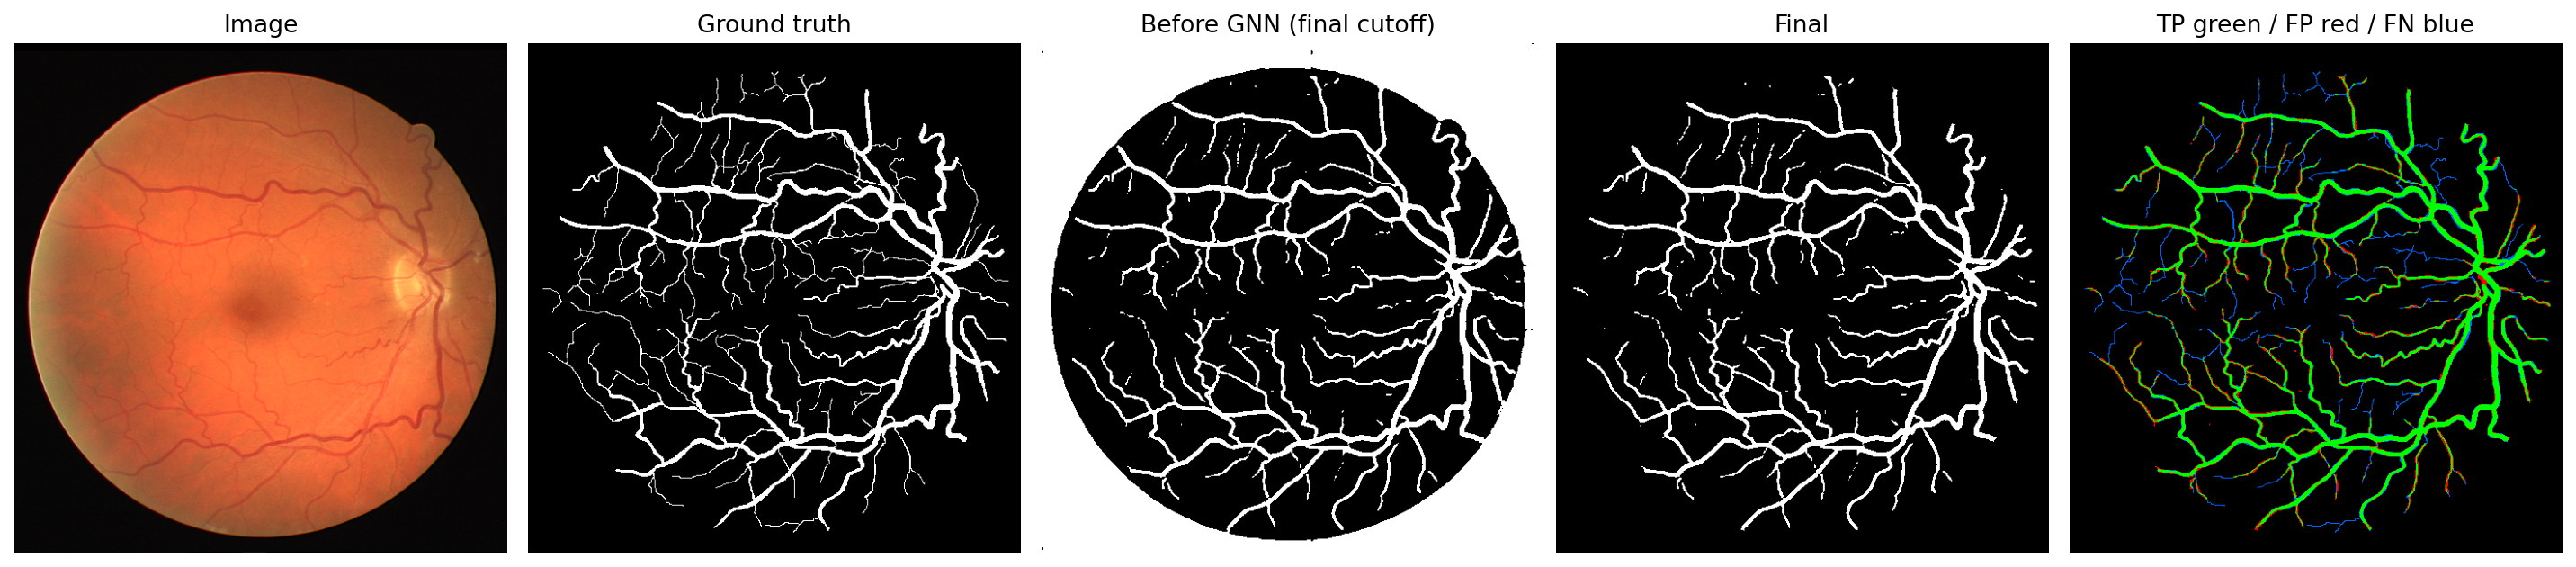

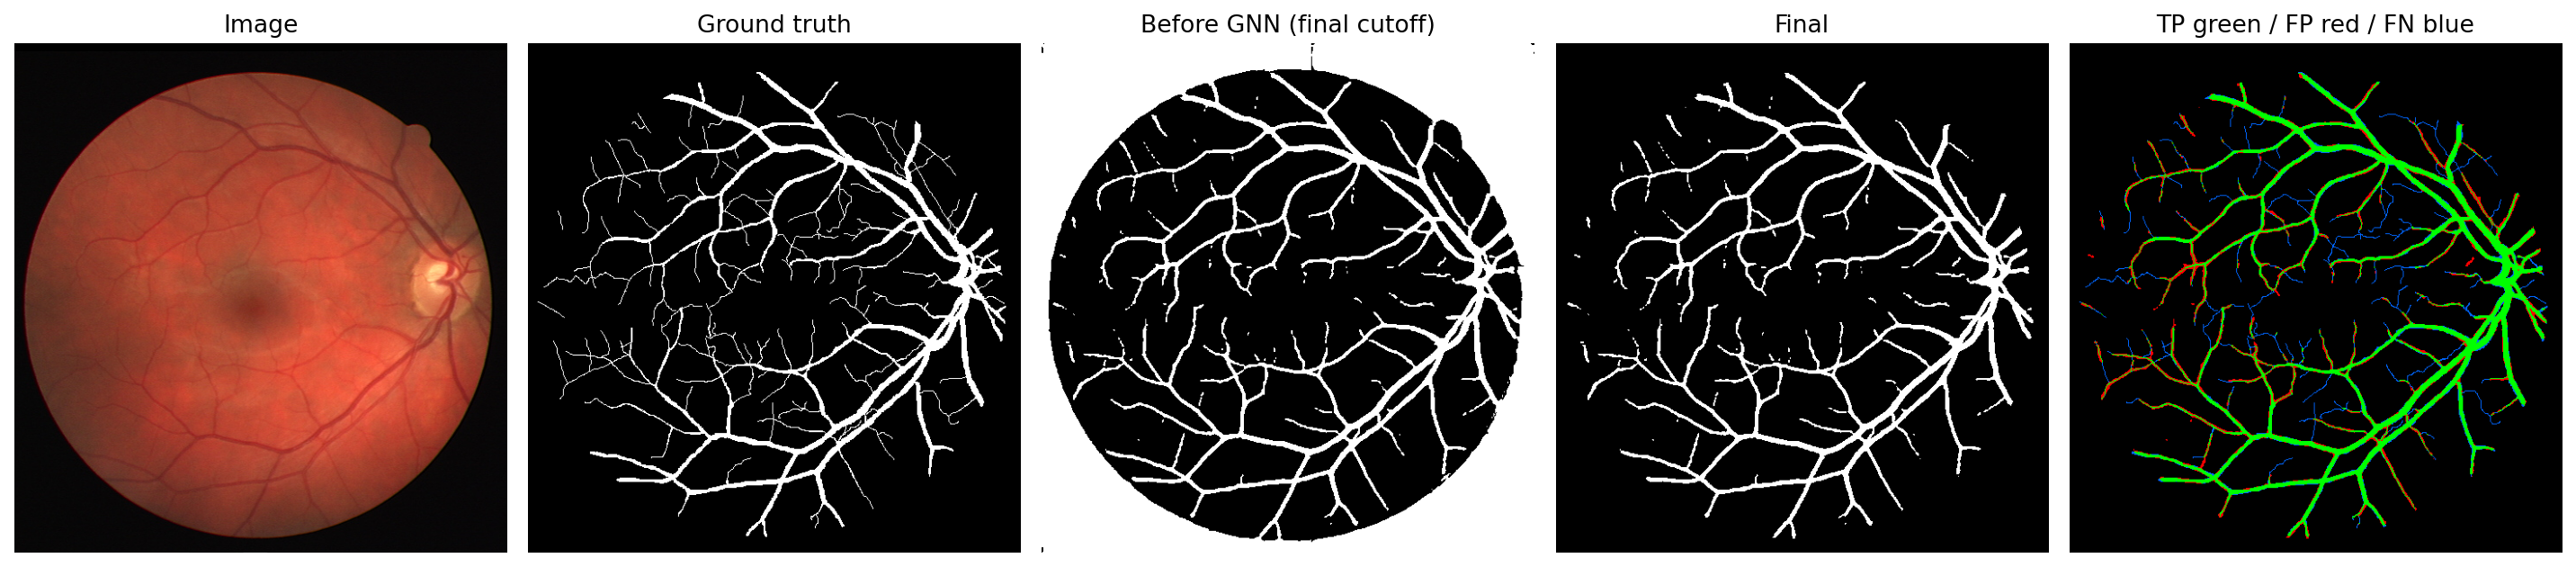

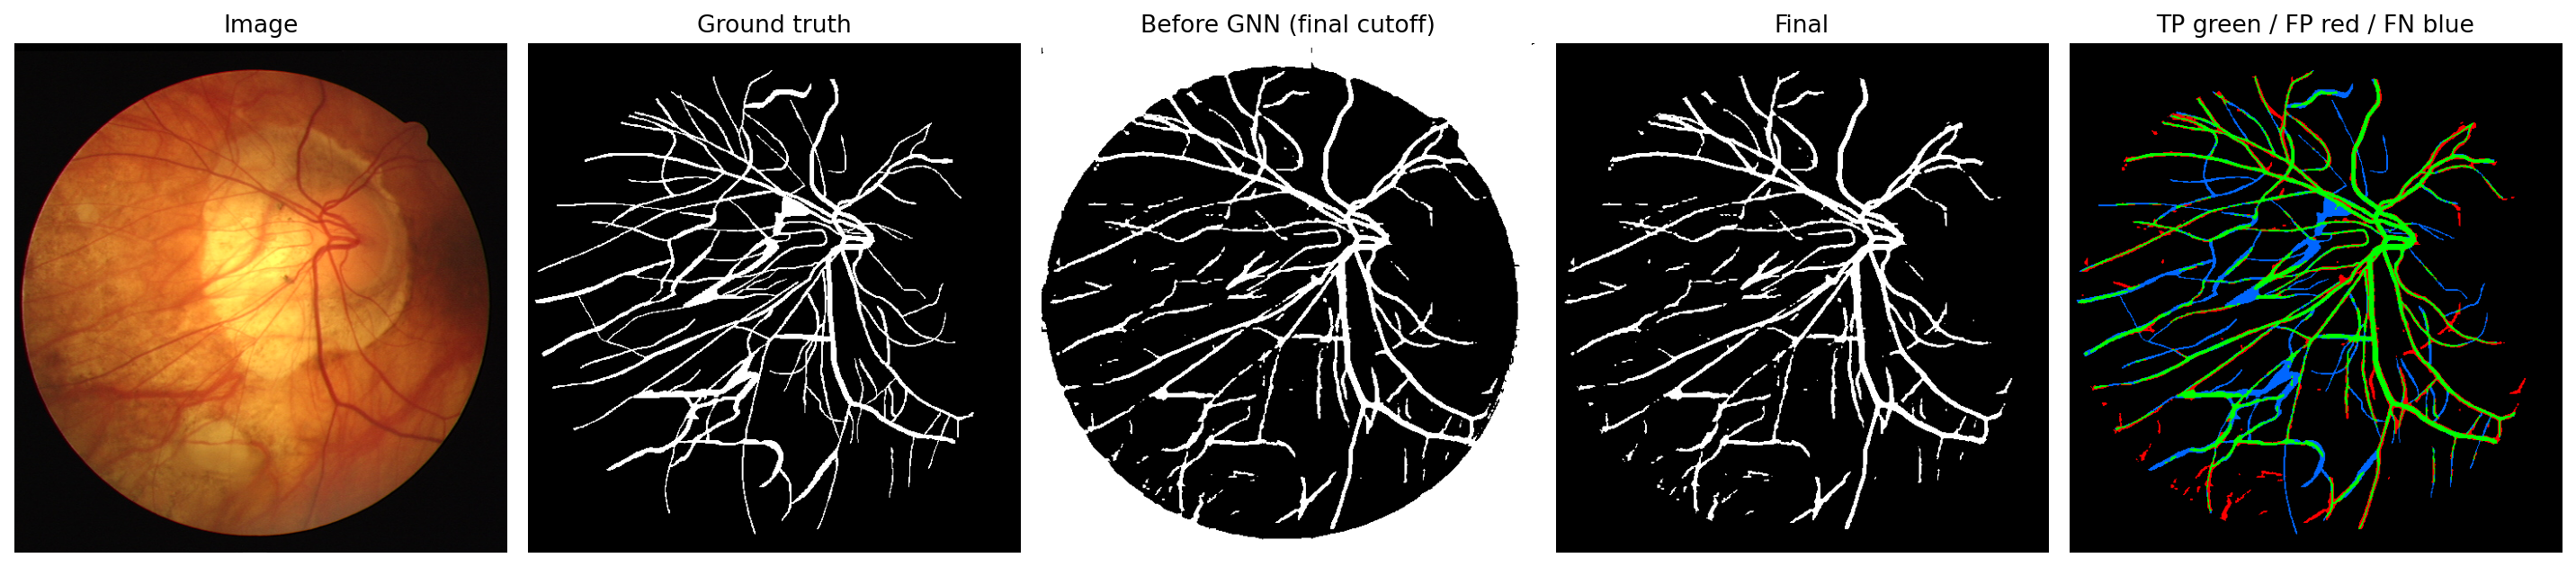

### STARE prediction examples

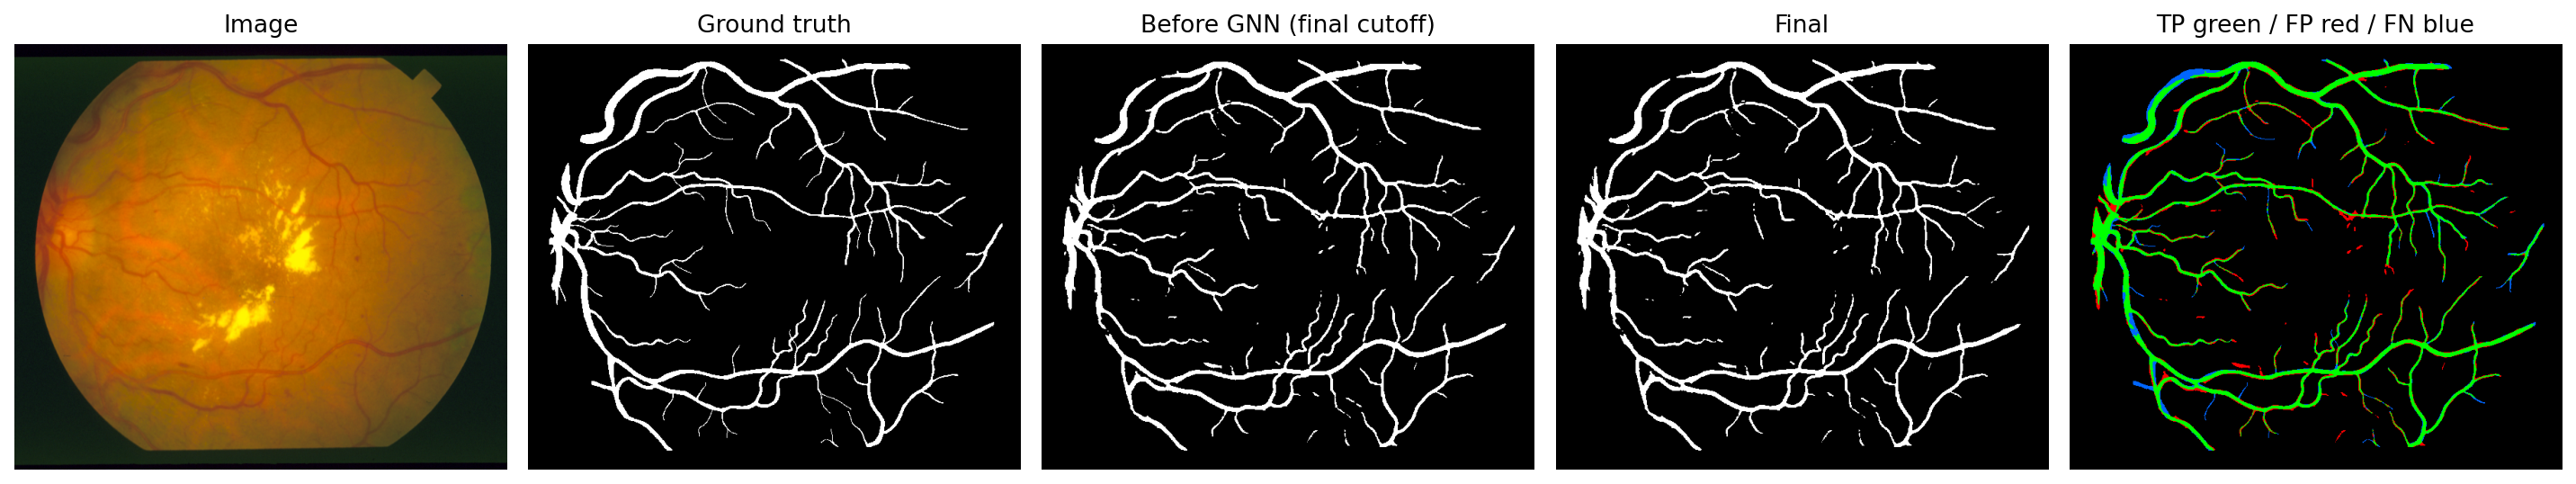

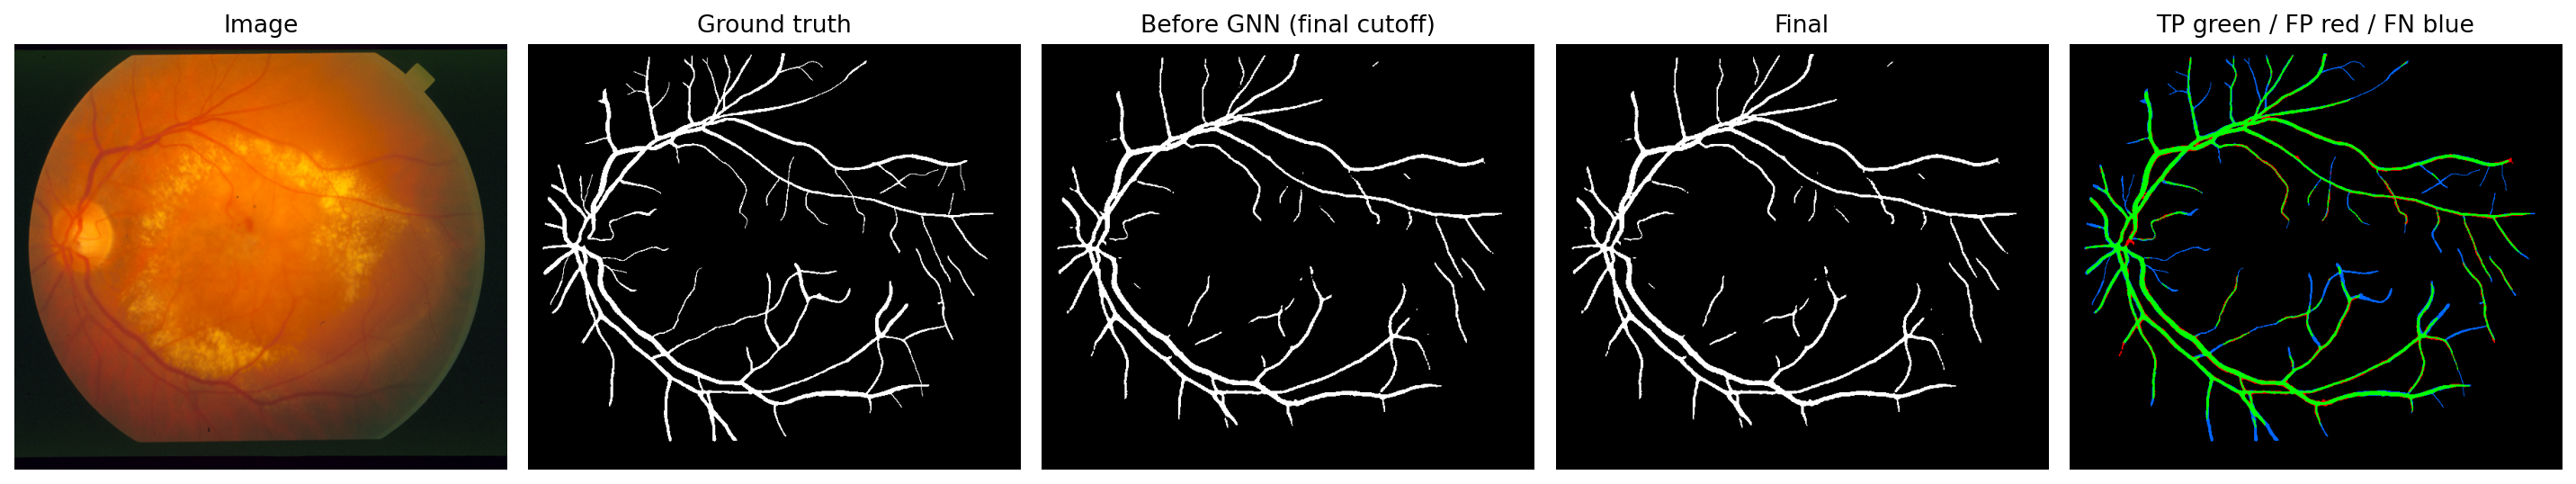

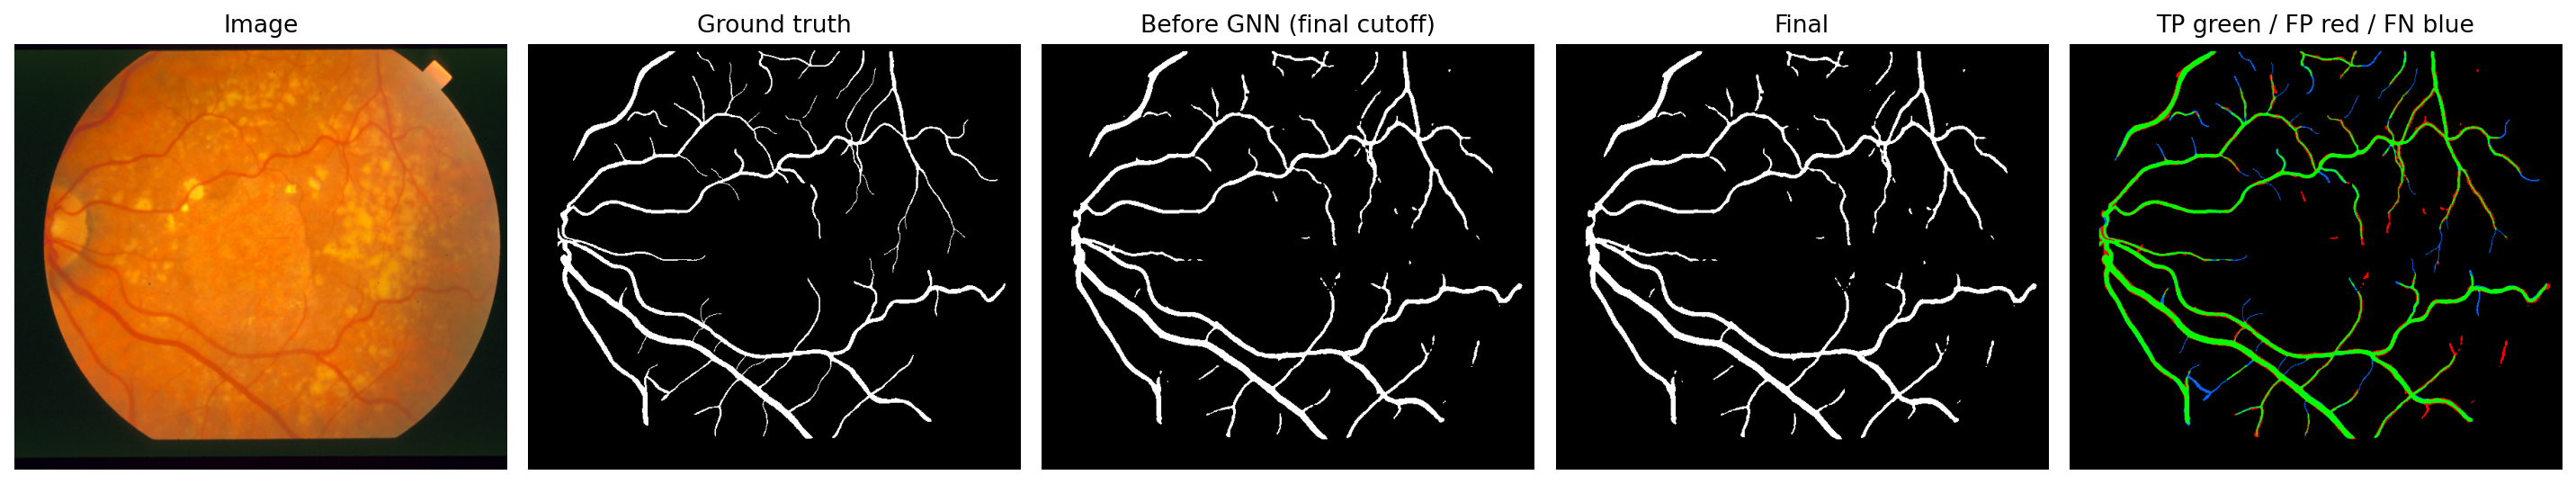

In [ ]:
generate_reports(RUN_ROOT,RESULTS,CFG)
from IPython.display import Image as DisplayImage
for dataset in CFG.datasets:
    examples=sorted((RUN_ROOT/dataset).rglob('*_prediction.png'))
    display(Markdown('### '+dataset+' prediction examples'))
    for path in examples[:3]: display(DisplayImage(filename=str(path)))


## 10. DOWNLOAD YOUR SCORES AND TRAINED MODEL
The small metrics archive downloads automatically. Saved CNN and GNN checkpoint links are listed below. STARE has one checkpoint pair per held-out fold, rather than a single model trained on all its images. Use the optional final cell to download **all** weights, predictions and reports (potentially several GB).

Checkpoints save model parameters, optimizer/scheduler state and the selected epoch. To rebuild the model, use the same config and `Segmenter('transgnn', CFG)`, then `checkpoint_load`. For the graph, construct `SparseGNN(node_dim, CFG)` using the saved graph feature width before loading its checkpoint.

In [ ]:
metrics_dir=RUN_ROOT/'metrics_download'
metrics_dir.mkdir(exist_ok=True)
for path in RUN_ROOT.glob('*.csv'): shutil.copy2(path,metrics_dir/path.name)
shutil.copy2(RUN_ROOT/'protocol.json',metrics_dir/'protocol.json')
metrics_zip=shutil.make_archive(str(RUN_ROOT)+'_METRICS','zip',root_dir=metrics_dir)
from google.colab import files
files.download(metrics_zip)
display(Markdown('### Your saved trained models'))
for checkpoint in sorted(RUN_ROOT.rglob('*_best.pt')):
    print(checkpoint.relative_to(RUN_ROOT))
    display(FileLink(str(checkpoint)))
print('Use Colab’s Files panel to download individual checkpoints if a link does not open.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Your saved trained models

DRIVE/seed_42/transgnn/internal_holdout/cnn_best.pt


/content/transgnn_results/final/cc4af3794b85e67d/DRIVE/seed_42/transgnn/internal_holdout/cnn_best.pt

...

STARE/seed_42/transgnn/fold_im0324/cnn_best.pt


/content/transgnn_results/final/cc4af3794b85e67d/STARE/seed_42/transgnn/fold_im0324/cnn_best.pt

STARE/seed_42/transgnn/fold_im0324/gnn_best.pt


/content/transgnn_results/final/cc4af3794b85e67d/STARE/seed_42/transgnn/fold_im0324/gnn_best.pt

Use Colab’s Files panel to download individual checkpoints if a link does not open.


### Optional: download all trained weights and predictions
Run this cell separately if you want the large complete archive. It is disabled during Run all to avoid a multi-GB download. **All model files are already saved in the results folder.**

In [ ]:
DOWNLOAD_ALL_MODEL_FILES = False
if DOWNLOAD_ALL_MODEL_FILES:
    archive=shutil.make_archive(str(RUN_ROOT)+'_MODELS_AND_RESULTS','zip',root_dir=RUN_ROOT)
    files.download(archive)


### Metric/protocol details
- FOV: DRIVE uses supplied official masks. STARE uses an image-derived mask if no supplied FOV is configured; it never uses the vessel label to define FOV.
- SSIM: binary segmentation SSIM over full 7×7 windows inside FOV. HD95: maximum of directed surface-distance 95th percentiles. ASSD: pooled directed surface distances.
- Topology: clDice, component/endpoint count errors and tolerance-based junction/endpoint metrics. Junctions, widths and curvature are algorithmic proxies.
- Thresholds and checkpoints come only from inner validation. GNN training uses only training labels. Its sparse graph uses CNN predictions and deep features; its correction is rasterized into the final segmentation.
- This streamlined run uses the complete model and one seed. Baseline/multi-seed configuration remains available in section 2 if you later need the full ablation study.
- Code was checked on synthetic inputs; your real Dice and other scores are generated only after your uploaded datasets finish training/evaluation.